# COMP5329/COMP4329 Assignment 2

## Project title
**Do Masked Autoencoders Learn Less Texture-Biased Representations Than Standard Autoencoders?**

## Core hypothesis
A standard autoencoder can partially solve reconstruction through local pixel/statistical shortcuts. A masked autoencoder removes many of those local shortcuts by hiding random patches, forcing the encoder to integrate broader image context. If this hypothesis is correct, MAE representations should:

1. transfer at least as well as AE representations under linear probing;
2. degrade less under low-pass filtering, where fine texture is removed but global structure remains;
3. behave differently under high-pass and local-texture perturbations;
4. show a systematic relationship between masking ratio and texture/frequency sensitivity.






## 1. Imports and environment setup

This cell imports the main libraries needed for training, evaluation, plotting, and saving results. It also checks the available device so the notebook can run on GPU if possible.

In [ ]:
# If running in a fresh environment and packages are missing, uncomment:
# !pip install -q scikit-learn pandas matplotlib tqdm

import os
import json
import math
import time
import random
import platform
import warnings
from dataclasses import dataclass, asdict, field
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Callable, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from scipy.stats import spearmanr
from scipy.spatial.distance import pdist, squareform

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, Dataset

import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF

warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
Python: 3.12.12
PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
GPU: Tesla T4


## 2. Configuration

This cell sets the main experiment settings, such as dataset choice, batch size, number of epochs, model size, mask ratio, and output folders.

In [ ]:
# Change this first.
# - "SMOKE": fast end-to-end debugging using a small subset.
# - "BALANCED": recommended main course-project run.
# - "FULL_HONOURS": more expensive, multi-seed, better for robust final evidence.
# - "HD_PLUS": stronger evidence package for an 85+/90 target if GPU time permits.
RUN_PRESET = "BALANCED"  # "SMOKE", "BALANCED", "FULL_HONOURS", or "HD_PLUS"


@dataclass
class ExperimentConfig:
    # Dataset
    dataset: str = "STL10"                 # "STL10", "CIFAR10", or "FAKEDATA"
    data_root: str = "./data"
    img_size: int = 96
    num_classes: int = 10
    download: bool = True

    # Compute / reproducibility
    seed: int = 42
    deterministic: bool = False            # True improves reproducibility but may slow training
    num_workers: int = 0  # stable default for Kaggle/papermill; set to 2 for faster interactive runs
    use_amp: bool = True
    force_retrain: bool = False
    max_pretrain_samples: Optional[int] = 25000
    max_probe_train_samples: Optional[int] = None
    max_test_samples: Optional[int] = None

    # Architecture
    patch_size: int = 16
    embed_dim: int = 192
    depth: int = 4
    num_heads: int = 4
    decoder_depth: int = 2
    mlp_ratio: float = 4.0
    dropout: float = 0.0

    # Training
    batch_size: int = 128
    epochs_pretrain: int = 40
    lr_pretrain: float = 1.5e-4
    min_lr: float = 1e-6
    weight_decay: float = 0.05
    warmup_epochs: int = 5
    grad_clip: float = 1.0

    # Models to run
    include_ae: bool = True
    include_dae: bool = True
    dae_noise_std: float = 0.25
    mae_mask_ratios: List[float] = field(default_factory=lambda: [0.25, 0.50, 0.75])

    # Evaluation
    probe_seeds: List[int] = field(default_factory=lambda: [0, 1, 2])
    canonical_probe_seed: int = 0
    linear_probe_max_iter: int = 2000
    knn_k: int = 5
    rsa_samples: int = 500

    # Additional HD+/85+ evidence checks
    sample_efficiency_fractions: List[float] = field(default_factory=lambda: [0.10, 0.25, 0.50, 1.00])
    bootstrap_iterations: int = 2000
    bootstrap_confidence: float = 0.95
    hybrid_cue_max_samples: Optional[int] = 1000
    hybrid_shape_cutoff: float = 0.25
    hybrid_texture_cutoff: float = 0.35

    # Fourier/texture evaluation
    fourier_cutoffs: List[float] = field(default_factory=lambda: [0.15, 0.25, 0.35, 0.50])
    primary_lowpass_cutoff: float = 0.25
    primary_highpass_cutoff: float = 0.35
    local_shuffle_block_size: int = 8
    blur_kernel_size: int = 7
    blur_sigma: float = 1.5

    # Output
    output_dir: str = "/kaggle/working/mae_texture_bias" if os.path.exists("/kaggle/working") else "./mae_texture_bias"


def make_config(preset: str) -> ExperimentConfig:
    cfg = ExperimentConfig()

    if preset.upper() == "SMOKE":
        cfg.dataset = "FAKEDATA"
        cfg.img_size = 64
        cfg.patch_size = 8
        cfg.embed_dim = 96
        cfg.depth = 2
        cfg.num_heads = 4
        cfg.decoder_depth = 1
        cfg.batch_size = 64
        cfg.epochs_pretrain = 2
        cfg.max_pretrain_samples = 512
        cfg.max_probe_train_samples = 512
        cfg.max_test_samples = 256
        cfg.mae_mask_ratios = [0.75]
        cfg.probe_seeds = [0]
        cfg.sample_efficiency_fractions = [0.50, 1.00]
        cfg.bootstrap_iterations = 200
        cfg.hybrid_cue_max_samples = 100
        cfg.rsa_samples = 100

    elif preset.upper() == "BALANCED":
        # Recommended default: feasible while still producing serious evidence.
        cfg.dataset = "STL10"
        cfg.img_size = 96
        cfg.patch_size = 16
        cfg.embed_dim = 192
        cfg.depth = 4
        cfg.num_heads = 4
        cfg.decoder_depth = 2
        cfg.batch_size = 128
        cfg.epochs_pretrain = 40
        cfg.max_pretrain_samples = 25000       # Set to None for full STL-10 unlabeled
        cfg.max_probe_train_samples = None
        cfg.max_test_samples = None
        cfg.mae_mask_ratios = [0.25, 0.50, 0.75]
        cfg.probe_seeds = [0, 1, 2]
        cfg.sample_efficiency_fractions = [0.10, 0.25, 0.50, 1.00]
        cfg.bootstrap_iterations = 2000
        cfg.hybrid_cue_max_samples = 1000
        cfg.rsa_samples = 500

    elif preset.upper() == "FULL_HONOURS":
        # Expensive but stronger: use if GPU time permits.
        cfg.dataset = "STL10"
        cfg.img_size = 96
        cfg.patch_size = 16
        cfg.embed_dim = 256
        cfg.depth = 6
        cfg.num_heads = 8
        cfg.decoder_depth = 3
        cfg.batch_size = 128
        cfg.epochs_pretrain = 100
        cfg.max_pretrain_samples = None
        cfg.max_probe_train_samples = None
        cfg.max_test_samples = None
        cfg.mae_mask_ratios = [0.25, 0.50, 0.75, 0.90]
        cfg.probe_seeds = [0, 1, 2, 3, 4]
        cfg.sample_efficiency_fractions = [0.05, 0.10, 0.25, 0.50, 1.00]
        cfg.bootstrap_iterations = 5000
        cfg.hybrid_cue_max_samples = 2000
        cfg.rsa_samples = 1000

    elif preset.upper() == "HD_PLUS":
        # Stronger-than-balanced preset designed for an 85+/90 evidence package.
        # It keeps the model feasible but expands the evaluation battery.
        cfg.dataset = "STL10"
        cfg.img_size = 96
        cfg.patch_size = 16
        cfg.embed_dim = 256
        cfg.depth = 6
        cfg.num_heads = 8
        cfg.decoder_depth = 3
        cfg.batch_size = 128
        cfg.epochs_pretrain = 75
        cfg.max_pretrain_samples = None
        cfg.max_probe_train_samples = None
        cfg.max_test_samples = None
        cfg.mae_mask_ratios = [0.25, 0.50, 0.75]
        cfg.probe_seeds = [0, 1, 2, 3, 4]
        cfg.sample_efficiency_fractions = [0.05, 0.10, 0.25, 0.50, 1.00]
        cfg.bootstrap_iterations = 5000
        cfg.hybrid_cue_max_samples = 2000
        cfg.rsa_samples = 1000

    else:
        raise ValueError(f"Unknown RUN_PRESET: {preset}")

    return cfg


CFG = make_config(RUN_PRESET)
OUT = Path(CFG.output_dir)
CKPT_DIR = OUT / "checkpoints"
FIG_DIR = OUT / "figures"
TABLE_DIR = OUT / "tables"
for p in [OUT, CKPT_DIR, FIG_DIR, TABLE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(CFG), indent=2))
print("Output directory:", OUT.resolve())

{
  "dataset": "STL10",
  "data_root": "./data",
  "img_size": 96,
  "num_classes": 10,
  "download": true,
  "seed": 42,
  "deterministic": false,
  "num_workers": 0,
  "use_amp": true,
  "force_retrain": false,
  "max_pretrain_samples": 25000,
  "max_probe_train_samples": null,
  "max_test_samples": null,
  "patch_size": 16,
  "embed_dim": 192,
  "depth": 4,
  "num_heads": 4,
  "decoder_depth": 2,
  "mlp_ratio": 4.0,
  "dropout": 0.0,
  "batch_size": 128,
  "epochs_pretrain": 40,
  "lr_pretrain": 0.00015,
  "min_lr": 1e-06,
  "weight_decay": 0.05,
  "warmup_epochs": 5,
  "grad_clip": 1.0,
  "include_ae": true,
  "include_dae": true,
  "dae_noise_std": 0.25,
  "mae_mask_ratios": [
    0.25,
    0.5,
    0.75
  ],
  "probe_seeds": [
    0,
    1,
    2
  ],
  "canonical_probe_seed": 0,
  "linear_probe_max_iter": 2000,
  "knn_k": 5,
  "rsa_samples": 500,
  "sample_efficiency_fractions": [
    0.1,
    0.25,
    0.5,
    1.0
  ],
  "bootstrap_iterations": 2000,
  "bootstrap_confidence": 

## 3. Reproducibility helpers

This cell sets random seeds so the experiment is more reproducible. It also defines small helper functions for timing, saving files, and logging results.

In [ ]:
def set_seed(seed: int, deterministic: bool = False) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    else:
        torch.backends.cudnn.deterministic = False
        torch.backends.cudnn.benchmark = True


set_seed(CFG.seed, CFG.deterministic)


def now() -> str:
    return time.strftime("%Y-%m-%d %H:%M:%S")


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def save_json(obj: Any, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


def load_json(path: Path) -> Any:
    with open(path, "r") as f:
        return json.load(f)

## 4. Data loading

Important design choice: pretraining may use stochastic augmentations, but evaluation should be deterministic.

This notebook therefore creates separate datasets/loaders:

- `pretrain_loader`: stochastic augmentation for self-supervised reconstruction training.
- `probe_train_loader`: deterministic images for linear-probe feature extraction.
- `probe_test_loader`: deterministic images for clean evaluation.
- perturbed test loaders: deterministic Fourier/texture perturbations applied to the same test images.



In [ ]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def make_transforms(img_size: int, train: bool) -> T.Compose:
    if train:
        return T.Compose([
            T.Resize((img_size, img_size)),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomCrop(img_size, padding=max(2, img_size // 24)),
            T.ToTensor(),
            T.Normalize(mean=IMAGENET_MEAN.view(-1).tolist(), std=IMAGENET_STD.view(-1).tolist()),
        ])
    return T.Compose([
        T.Resize((img_size, img_size)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN.view(-1).tolist(), std=IMAGENET_STD.view(-1).tolist()),
    ])


def maybe_subset(ds: Dataset, max_samples: Optional[int], seed: int) -> Dataset:
    if max_samples is None or max_samples >= len(ds):
        return ds
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(ds), size=max_samples, replace=False)
    return Subset(ds, idx.tolist())


def build_datasets(cfg: ExperimentConfig) -> Tuple[Dataset, Dataset, Dataset]:
    train_tf = make_transforms(cfg.img_size, train=True)
    eval_tf = make_transforms(cfg.img_size, train=False)

    root = cfg.data_root

    if cfg.dataset.upper() == "STL10":
        # STL-10 gives an unlabeled split, which is appropriate for self-supervised pretraining.
        pretrain_ds = torchvision.datasets.STL10(root=root, split="unlabeled", download=cfg.download, transform=train_tf)
        probe_train_ds = torchvision.datasets.STL10(root=root, split="train", download=cfg.download, transform=eval_tf)
        probe_test_ds = torchvision.datasets.STL10(root=root, split="test", download=cfg.download, transform=eval_tf)

    elif cfg.dataset.upper() == "CIFAR10":
        pretrain_ds = torchvision.datasets.CIFAR10(root=root, train=True, download=cfg.download, transform=train_tf)
        probe_train_ds = torchvision.datasets.CIFAR10(root=root, train=True, download=cfg.download, transform=eval_tf)
        probe_test_ds = torchvision.datasets.CIFAR10(root=root, train=False, download=cfg.download, transform=eval_tf)

    elif cfg.dataset.upper() == "FAKEDATA":
        # Useful only for smoke-testing code paths. Do not use FakeData for the final paper.
        pretrain_ds = torchvision.datasets.FakeData(size=1024, image_size=(3, cfg.img_size, cfg.img_size),
                                                    num_classes=cfg.num_classes, transform=eval_tf)
        probe_train_ds = torchvision.datasets.FakeData(size=1024, image_size=(3, cfg.img_size, cfg.img_size),
                                                       num_classes=cfg.num_classes, transform=eval_tf)
        probe_test_ds = torchvision.datasets.FakeData(size=512, image_size=(3, cfg.img_size, cfg.img_size),
                                                      num_classes=cfg.num_classes, transform=eval_tf)
    else:
        raise ValueError(f"Unsupported dataset: {cfg.dataset}")

    pretrain_ds = maybe_subset(pretrain_ds, cfg.max_pretrain_samples, cfg.seed)
    probe_train_ds = maybe_subset(probe_train_ds, cfg.max_probe_train_samples, cfg.seed + 1)
    probe_test_ds = maybe_subset(probe_test_ds, cfg.max_test_samples, cfg.seed + 2)

    return pretrain_ds, probe_train_ds, probe_test_ds


def build_loaders(cfg: ExperimentConfig):
    # DataLoader worker stability note: num_workers=0 avoids Kaggle/papermill
    # multiprocessing cleanup errors after exceptions. Increase to 2 only after
    # the notebook has run successfully end-to-end.
    pretrain_ds, probe_train_ds, probe_test_ds = build_datasets(cfg)
    pretrain_loader = DataLoader(pretrain_ds, batch_size=cfg.batch_size, shuffle=True,
                                 num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available(), drop_last=True)
    probe_train_loader = DataLoader(probe_train_ds, batch_size=cfg.batch_size, shuffle=False,
                                    num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())
    probe_test_loader = DataLoader(probe_test_ds, batch_size=cfg.batch_size, shuffle=False,
                                   num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())
    return pretrain_loader, probe_train_loader, probe_test_loader


pretrain_loader, probe_train_loader, probe_test_loader = build_loaders(CFG)

print(f"Pretrain images: {len(pretrain_loader.dataset):,}")
print(f"Probe train images: {len(probe_train_loader.dataset):,}")
print(f"Probe test images: {len(probe_test_loader.dataset):,}")
print(f"Pretrain batches: {len(pretrain_loader):,}")

100%|██████████| 2.64G/2.64G [07:56<00:00, 5.54MB/s]


Pretrain images: 25,000
Probe train images: 5,000
Probe test images: 8,000
Pretrain batches: 195


## 5. Visual sanity check

This cell shows sample images from the dataset. This helps confirm that the data has loaded correctly before training starts.

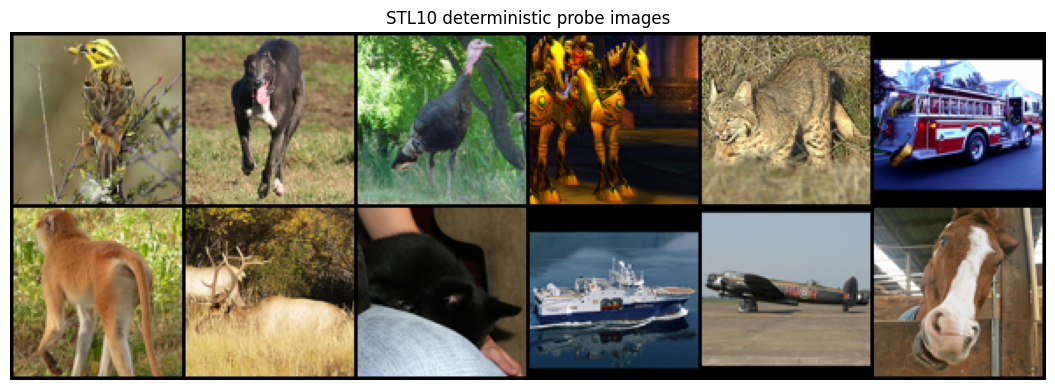

In [ ]:
def denormalise_batch(x: torch.Tensor) -> torch.Tensor:
    mean = IMAGENET_MEAN.to(x.device)
    std = IMAGENET_STD.to(x.device)
    if x.ndim == 4:
        mean = mean.unsqueeze(0)
        std = std.unsqueeze(0)
    return (x * std + mean).clamp(0, 1)


def show_image_grid(loader, n: int = 12, title: str = "Sample images") -> None:
    imgs, labels = next(iter(loader))
    imgs = denormalise_batch(imgs[:n]).cpu()
    grid = torchvision.utils.make_grid(imgs, nrow=min(6, n), padding=2)
    plt.figure(figsize=(12, 4))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    plt.title(title)
    plt.tight_layout()
    plt.show()


show_image_grid(probe_train_loader, n=12, title=f"{CFG.dataset} deterministic probe images")

## 6. Patch utilities

Both AE and MAE train by reconstructing image patches. To make the comparison fair, both use the same patchification and target normalisation.

The reconstruction loss uses per-patch normalisation. This prevents the loss from being dominated by simple brightness/contrast variation and follows the logic used in MAE-style reconstruction. For visualisation, the predictions are converted back to the original patch scale using the stored patch mean and standard deviation.

In [ ]:
def patchify(imgs: torch.Tensor, patch_size: int) -> torch.Tensor:
    """
    Convert images to flattened patches.

    imgs: (B, 3, H, W)
    returns: (B, N, 3 * patch_size * patch_size)
    """
    B, C, H, W = imgs.shape
    p = patch_size
    assert H % p == 0 and W % p == 0, f"Image size {(H, W)} not divisible by patch size {p}"
    h = H // p
    w = W // p
    x = imgs.reshape(B, C, h, p, w, p)
    x = x.permute(0, 2, 4, 1, 3, 5)
    x = x.reshape(B, h * w, C * p * p)
    return x


def unpatchify(patches: torch.Tensor, patch_size: int, img_size: int) -> torch.Tensor:
    """
    Convert flattened patches back to images.

    patches: (B, N, 3 * patch_size * patch_size)
    returns: (B, 3, H, W)
    """
    B, N, D = patches.shape
    p = patch_size
    h = w = img_size // p
    assert N == h * w, f"Expected {h*w} patches, got {N}"
    x = patches.reshape(B, h, w, 3, p, p)
    x = x.permute(0, 3, 1, 4, 2, 5)
    x = x.reshape(B, 3, img_size, img_size)
    return x


def normalised_patch_target(imgs: torch.Tensor, patch_size: int, eps: float = 1e-6):
    raw = patchify(imgs, patch_size)
    mean = raw.mean(dim=-1, keepdim=True)
    std = raw.std(dim=-1, keepdim=True).clamp_min(eps)
    target = (raw - mean) / std
    return target, mean, std


def restore_patch_scale(pred_norm: torch.Tensor, patch_mean: torch.Tensor, patch_std: torch.Tensor) -> torch.Tensor:
    return pred_norm * patch_std + patch_mean

## 7. Model architecture

The central control in the project is that the AE, DAE, and MAE use the same ViT encoder. This is what allows the paper to attribute differences primarily to the reconstruction objective rather than to a different architecture.

Models:

- **AE**: sees all patches, reconstructs all patches.
- **DAE**: sees a noisy version of the image, reconstructs the clean image. This controls for whether MAE gains are just from a harder reconstruction task.
- **MAE**: sees only visible patches, reconstructs masked patches.

During downstream evaluation, all models encode the clean, unmasked image and the encoder is frozen.

In [ ]:
class PatchEmbed(nn.Module):
    def __init__(self, img_size: int, patch_size: int, in_chans: int = 3, embed_dim: int = 192):
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.grid_size = img_size // patch_size
        self.num_patches = self.grid_size ** 2
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.proj(x)
        x = x.flatten(2).transpose(1, 2)
        return x


class TransformerBlock(nn.Module):
    def __init__(self, dim: int, num_heads: int, mlp_ratio: float = 4.0, dropout: float = 0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, dim),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = self.norm1(x)
        attn_out, _ = self.attn(z, z, z, need_weights=False)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x


class ViTEncoder(nn.Module):
    """
    Compact ViT encoder.

    The class token is used as the downstream representation.
    This is held constant across AE, DAE, and MAE.
    """
    def __init__(self, cfg: ExperimentConfig):
        super().__init__()
        self.img_size = cfg.img_size
        self.patch_size = cfg.patch_size
        self.embed_dim = cfg.embed_dim

        self.patch_embed = PatchEmbed(cfg.img_size, cfg.patch_size, embed_dim=cfg.embed_dim)
        n = self.patch_embed.num_patches

        self.cls_token = nn.Parameter(torch.zeros(1, 1, cfg.embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n + 1, cfg.embed_dim))
        self.blocks = nn.ModuleList([
            TransformerBlock(cfg.embed_dim, cfg.num_heads, cfg.mlp_ratio, cfg.dropout)
            for _ in range(cfg.depth)
        ])
        self.norm = nn.LayerNorm(cfg.embed_dim)

        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, imgs: torch.Tensor, keep_ids: Optional[torch.Tensor] = None):
        B = imgs.shape[0]
        x = self.patch_embed(imgs)
        x = x + self.pos_embed[:, 1:, :]

        if keep_ids is not None:
            x = torch.gather(x, dim=1, index=keep_ids.unsqueeze(-1).expand(-1, -1, x.shape[-1]))

        cls = self.cls_token.expand(B, -1, -1) + self.pos_embed[:, :1, :]
        x = torch.cat([cls, x], dim=1)

        for block in self.blocks:
            x = block(x)
        x = self.norm(x)

        return x[:, 0], x[:, 1:]


class AE(nn.Module):
    """
    Standard autoencoder:
    - Encoder sees all patches.
    - Decoder reconstructs all patches.
    """
    def __init__(self, cfg: ExperimentConfig):
        super().__init__()
        self.cfg = cfg
        self.img_size = cfg.img_size
        self.patch_size = cfg.patch_size
        self.num_patches = (cfg.img_size // cfg.patch_size) ** 2
        self.decoder_dim = cfg.embed_dim // 2

        self.encoder = ViTEncoder(cfg)
        self.decoder_embed = nn.Linear(cfg.embed_dim, self.decoder_dim)
        self.decoder_pos = nn.Parameter(torch.zeros(1, self.num_patches, self.decoder_dim))
        self.decoder_blocks = nn.ModuleList([
            TransformerBlock(self.decoder_dim, max(1, self.decoder_dim // 64), cfg.mlp_ratio, cfg.dropout)
            for _ in range(cfg.decoder_depth)
        ])
        self.decoder_norm = nn.LayerNorm(self.decoder_dim)
        self.pred_head = nn.Linear(self.decoder_dim, cfg.patch_size * cfg.patch_size * 3)

        nn.init.trunc_normal_(self.decoder_pos, std=0.02)

    def decode(self, patch_feats: torch.Tensor) -> torch.Tensor:
        x = self.decoder_embed(patch_feats)
        x = x + self.decoder_pos
        for block in self.decoder_blocks:
            x = block(x)
        x = self.decoder_norm(x)
        pred = self.pred_head(x)
        return pred

    def forward(self, imgs: torch.Tensor, input_imgs: Optional[torch.Tensor] = None) -> Dict[str, torch.Tensor]:
        """
        imgs is always the clean target image.
        input_imgs is the image fed to the encoder. For a standard AE this is None/clean.
        For a DAE this is a noisy image.
        """
        if input_imgs is None:
            input_imgs = imgs

        cls, patch_feats = self.encoder(input_imgs)
        pred = self.decode(patch_feats)

        target, patch_mean, patch_std = normalised_patch_target(imgs, self.patch_size)
        loss = ((pred - target) ** 2).mean()

        return {
            "loss": loss,
            "pred": pred,
            "target": target,
            "patch_mean": patch_mean,
            "patch_std": patch_std,
        }

    @torch.no_grad()
    def encode(self, imgs: torch.Tensor) -> torch.Tensor:
        cls, _ = self.encoder(imgs)
        return cls

    @torch.no_grad()
    def reconstruct(self, imgs: torch.Tensor) -> torch.Tensor:
        out = self.forward(imgs)
        pred_raw = restore_patch_scale(out["pred"], out["patch_mean"], out["patch_std"])
        return unpatchify(pred_raw, self.patch_size, self.img_size)


class DenoisingAE(AE):
    """
    Denoising AE control:
    - Encoder receives a noisy image.
    - Decoder is trained to reconstruct the clean image.

    This is a stricter control than the original scaffold because the previous
    implementation effectively reconstructed the noisy input rather than the clean target.
    """
    def __init__(self, cfg: ExperimentConfig, noise_std: float = 0.25):
        super().__init__(cfg)
        self.noise_std = noise_std

    def forward(self, imgs: torch.Tensor) -> Dict[str, torch.Tensor]:
        noisy = imgs + torch.randn_like(imgs) * self.noise_std
        return super().forward(imgs, input_imgs=noisy)


class MAE(nn.Module):
    """
    Masked autoencoder:
    - Encoder only sees visible patches.
    - Decoder reconstructs masked patches.
    - Downstream evaluation encodes full unmasked images.
    """
    def __init__(self, cfg: ExperimentConfig, mask_ratio: Optional[float] = None):
        super().__init__()
        self.cfg = cfg
        self.img_size = cfg.img_size
        self.patch_size = cfg.patch_size
        self.num_patches = (cfg.img_size // cfg.patch_size) ** 2
        self.mask_ratio = cfg.mae_mask_ratios[0] if mask_ratio is None else mask_ratio
        self.decoder_dim = cfg.embed_dim // 2

        self.encoder = ViTEncoder(cfg)

        self.decoder_embed = nn.Linear(cfg.embed_dim, self.decoder_dim)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, self.decoder_dim))
        self.decoder_pos = nn.Parameter(torch.zeros(1, self.num_patches, self.decoder_dim))
        self.decoder_blocks = nn.ModuleList([
            TransformerBlock(self.decoder_dim, max(1, self.decoder_dim // 64), cfg.mlp_ratio, cfg.dropout)
            for _ in range(cfg.decoder_depth)
        ])
        self.decoder_norm = nn.LayerNorm(self.decoder_dim)
        self.pred_head = nn.Linear(self.decoder_dim, cfg.patch_size * cfg.patch_size * 3)

        nn.init.trunc_normal_(self.mask_token, std=0.02)
        nn.init.trunc_normal_(self.decoder_pos, std=0.02)

    def random_mask(self, B: int, N: int, ratio: float, device: torch.device):
        keep_n = max(1, int(N * (1.0 - ratio)))
        noise = torch.rand(B, N, device=device)
        ids_shuffle = torch.argsort(noise, dim=1)
        keep_ids = ids_shuffle[:, :keep_n]
        mask_ids = ids_shuffle[:, keep_n:]
        return keep_ids, mask_ids

    def decode(self, visible_feats: torch.Tensor, keep_ids: torch.Tensor, mask_ids: torch.Tensor) -> torch.Tensor:
        B = visible_feats.shape[0]
        x_vis = self.decoder_embed(visible_feats)
        D = x_vis.shape[-1]

        # AMP fix: under mixed precision, decoder_embed may produce float16/bfloat16
        # while learned parameters such as mask_token remain float32. torch.scatter_
        # requires the destination and source tensors to have exactly the same dtype.
        # Casting the positional tensors to x_vis.dtype keeps mixed-precision training
        # enabled without triggering: RuntimeError: scatter(): Expected self.dtype to be equal to src.dtype.
        mask_token = self.mask_token.to(device=x_vis.device, dtype=x_vis.dtype)
        decoder_pos = self.decoder_pos.to(device=x_vis.device, dtype=x_vis.dtype)

        x_full = mask_token.expand(B, self.num_patches, D).clone()
        x_full.scatter_(1, keep_ids.unsqueeze(-1).expand(-1, -1, D), x_vis)
        x_full = x_full + decoder_pos

        for block in self.decoder_blocks:
            x_full = block(x_full)
        x_full = self.decoder_norm(x_full)
        pred = self.pred_head(x_full)
        return pred

    def forward(self, imgs: torch.Tensor, mask_ratio: Optional[float] = None) -> Dict[str, torch.Tensor]:
        ratio = self.mask_ratio if mask_ratio is None else mask_ratio
        B = imgs.shape[0]
        N = self.num_patches

        keep_ids, mask_ids = self.random_mask(B, N, ratio, imgs.device)
        cls, visible_feats = self.encoder(imgs, keep_ids=keep_ids)
        pred = self.decode(visible_feats, keep_ids, mask_ids)

        target, patch_mean, patch_std = normalised_patch_target(imgs, self.patch_size)

        mask = torch.zeros(B, N, device=imgs.device)
        mask.scatter_(1, mask_ids, 1.0)

        per_patch_loss = ((pred - target) ** 2).mean(dim=-1)
        loss = (per_patch_loss * mask).sum() / mask.sum().clamp_min(1.0)

        return {
            "loss": loss,
            "pred": pred,
            "target": target,
            "mask": mask,
            "keep_ids": keep_ids,
            "mask_ids": mask_ids,
            "patch_mean": patch_mean,
            "patch_std": patch_std,
        }

    @torch.no_grad()
    def encode(self, imgs: torch.Tensor) -> torch.Tensor:
        cls, _ = self.encoder(imgs, keep_ids=None)
        return cls

    @torch.no_grad()
    def reconstruct(self, imgs: torch.Tensor, blend_visible: bool = True) -> torch.Tensor:
        out = self.forward(imgs, mask_ratio=self.mask_ratio)
        pred_raw = restore_patch_scale(out["pred"], out["patch_mean"], out["patch_std"])
        if blend_visible:
            true_raw = patchify(imgs, self.patch_size)
            mask = out["mask"].unsqueeze(-1)
            pred_raw = pred_raw * mask + true_raw * (1.0 - mask)
        return unpatchify(pred_raw, self.patch_size, self.img_size)

## 8. Model registry and sanity checks

This cell creates the model list for the experiment and checks that each model can run correctly on a small input batch.

In [ ]:
def build_model_specs(cfg: ExperimentConfig) -> Dict[str, nn.Module]:
    specs: Dict[str, nn.Module] = {}

    if cfg.include_ae:
        specs["AE"] = AE(cfg)

    if cfg.include_dae:
        specs[f"DAE_noise{cfg.dae_noise_std:.2f}"] = DenoisingAE(cfg, noise_std=cfg.dae_noise_std)

    for r in cfg.mae_mask_ratios:
        specs[f"MAE_{int(round(r * 100)):02d}"] = MAE(cfg, mask_ratio=r)

    return specs


model_specs = build_model_specs(CFG)

for name, model in model_specs.items():
    print(f"{name:14s} | parameters: {count_parameters(model):,}")

# Forward-pass sanity check on one batch
imgs, labels = next(iter(pretrain_loader))
imgs = imgs[:2].to(DEVICE)
for name, model in model_specs.items():
    model = model.to(DEVICE)
    with torch.no_grad():
        out = model(imgs)
    assert "loss" in out and torch.isfinite(out["loss"]).item(), f"{name} produced invalid loss"
    print(f"{name:14s} | sanity loss: {out['loss'].item():.4f}")
    model.cpu()
torch.cuda.empty_cache()

AE             | parameters: 2,255,136
DAE_noise0.25  | parameters: 2,255,136
MAE_25         | parameters: 2,255,232
MAE_50         | parameters: 2,255,232
MAE_75         | parameters: 2,255,232
AE             | sanity loss: 1.3210
DAE_noise0.25  | sanity loss: 1.3350
MAE_25         | sanity loss: 1.3547
MAE_50         | sanity loss: 1.3289
MAE_75         | sanity loss: 1.3378


## 9. Pretraining

All models are trained with the same optimiser, learning-rate schedule, number of epochs, batch size, and data.

This is crucial for a fair comparison. If the MAE receives longer training, a larger encoder, or a different optimiser, then the experiment cannot isolate the effect of masking.

Checkpoints are automatically saved and re-used unless `CFG.force_retrain = True`.

In [ ]:
def cosine_lr(epoch: int, total_epochs: int, warmup_epochs: int, base_lr: float, min_lr: float) -> float:
    if warmup_epochs > 0 and epoch <= warmup_epochs:
        return base_lr * epoch / max(1, warmup_epochs)
    progress = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
    return min_lr + 0.5 * (base_lr - min_lr) * (1.0 + math.cos(math.pi * progress))


def set_optimizer_lr(optimizer: torch.optim.Optimizer, lr: float) -> None:
    for group in optimizer.param_groups:
        group["lr"] = lr


def checkpoint_path(name: str, cfg: ExperimentConfig) -> Path:
    safe_name = name.replace("/", "_").replace(" ", "_")
    return CKPT_DIR / f"{safe_name}_{cfg.dataset}_{cfg.img_size}px_seed{cfg.seed}.pt"


def history_path(name: str, cfg: ExperimentConfig) -> Path:
    safe_name = name.replace("/", "_").replace(" ", "_")
    return CKPT_DIR / f"{safe_name}_{cfg.dataset}_{cfg.img_size}px_seed{cfg.seed}_history.json"


def train_one_epoch(model: nn.Module, loader: DataLoader, optimizer, scaler, cfg: ExperimentConfig, epoch: int) -> float:
    model.train()
    losses = []

    pbar = tqdm(loader, desc=f"epoch {epoch}", leave=False)
    for imgs, _ in pbar:
        imgs = imgs.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=(cfg.use_amp and DEVICE.type == "cuda")):
            out = model(imgs)
            loss = out["loss"]

        scaler.scale(loss).backward()
        if cfg.grad_clip is not None and cfg.grad_clip > 0:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
        scaler.step(optimizer)
        scaler.update()

        losses.append(float(loss.detach().cpu()))
        pbar.set_postfix(loss=np.mean(losses[-20:]))

    return float(np.mean(losses))


def pretrain_model(name: str, model: nn.Module, loader: DataLoader, cfg: ExperimentConfig) -> Tuple[nn.Module, List[float]]:
    ckpt = checkpoint_path(name, cfg)
    hist_file = history_path(name, cfg)

    model = model.to(DEVICE)

    if ckpt.exists() and hist_file.exists() and not cfg.force_retrain:
        print(f"[{name}] loading existing checkpoint: {ckpt}")
        try:
            state = torch.load(ckpt, map_location=DEVICE)
            model.load_state_dict(state["model"])
            history = load_json(hist_file)
            return model, history
        except RuntimeError as e:
            # This can happen if you switch presets, because BALANCED/HD_PLUS/FULL_HONOURS
            # use different model widths/depths but may share the same output directory.
            # Rather than crashing after a long setup phase, fall back to retraining this model.
            print(f"[{name}] existing checkpoint is incompatible with the current architecture.")
            print("Reason:", str(e).split("\n")[0])
            print(f"[{name}] retraining from scratch. To force this behaviour manually, set force_retrain=True.")

    print(f"\n[{now()}] Pretraining {name}")
    print(f"Checkpoint will be saved to: {ckpt}")

    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr_pretrain, weight_decay=cfg.weight_decay)
    scaler = torch.cuda.amp.GradScaler(enabled=(cfg.use_amp and DEVICE.type == "cuda"))

    history = []
    for epoch in range(1, cfg.epochs_pretrain + 1):
        lr = cosine_lr(epoch, cfg.epochs_pretrain, cfg.warmup_epochs, cfg.lr_pretrain, cfg.min_lr)
        set_optimizer_lr(optimizer, lr)

        loss = train_one_epoch(model, loader, optimizer, scaler, cfg, epoch)
        history.append(loss)

        print(f"[{name}] epoch {epoch:03d}/{cfg.epochs_pretrain:03d} | lr={lr:.2e} | loss={loss:.5f}")

        # Save periodically to protect against notebook crashes.
        if epoch == 1 or epoch % 10 == 0 or epoch == cfg.epochs_pretrain:
            torch.save({"model": model.state_dict(), "cfg": asdict(cfg), "epoch": epoch}, ckpt)
            save_json(history, hist_file)

    return model, history


def plot_pretrain_histories(histories: Dict[str, List[float]]) -> None:
    plt.figure(figsize=(9, 5))
    for name, hist in histories.items():
        plt.plot(np.arange(1, len(hist) + 1), hist, label=name, linewidth=2)
    plt.xlabel("Pretraining epoch")
    plt.ylabel("Reconstruction loss")
    plt.title("Self-supervised pretraining curves")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    path = FIG_DIR / "pretraining_loss_curves.png"
    plt.savefig(path, dpi=200)
    plt.show()
    print("Saved:", path)

## 10. Run pretraining

This cell trains the AE, DAE, and MAE models using the same training setup. It also saves checkpoints and logs the pretraining losses.


[2026-05-22 01:26:47] Pretraining AE
Checkpoint will be saved to: /kaggle/working/mae_texture_bias/checkpoints/AE_STL10_96px_seed42.pt


/tmp/ipykernel_23/3923934749.py:78: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(cfg.use_amp and DEVICE.type == "cuda"))


epoch 1:   0%|          | 0/195 [00:00<?, ?it/s]

/tmp/ipykernel_23/3923934749.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(cfg.use_amp and DEVICE.type == "cuda")):


[AE] epoch 001/040 | lr=3.00e-05 | loss=0.96543


epoch 2:   0%|          | 0/195 [00:00<?, ?it/s]

... (393 outputs left out)

epoch 39:   0%|          | 0/195 [00:00<?, ?it/s]

[MAE_75] epoch 039/040 | lr=1.30e-06 | loss=0.64926


epoch 40:   0%|          | 0/195 [00:00<?, ?it/s]

[MAE_75] epoch 040/040 | lr=1.00e-06 | loss=0.64956


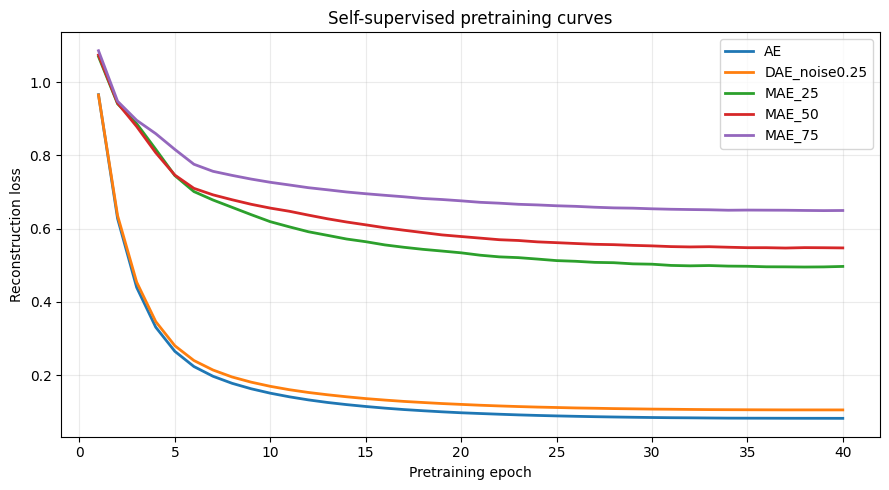

Saved: /kaggle/working/mae_texture_bias/figures/pretraining_loss_curves.png


In [ ]:
set_seed(CFG.seed, CFG.deterministic)

trained_models: Dict[str, nn.Module] = {}
pretrain_histories: Dict[str, List[float]] = {}

for name, model in build_model_specs(CFG).items():
    model, hist = pretrain_model(name, model, pretrain_loader, CFG)
    trained_models[name] = model.cpu()
    pretrain_histories[name] = hist
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

plot_pretrain_histories(pretrain_histories)

save_json(pretrain_histories, OUT / "pretrain_histories.json")

## 11. Reconstruction visualisation

This cell displays original and reconstructed images. This gives a visual check of what each model has learned to reconstruct.

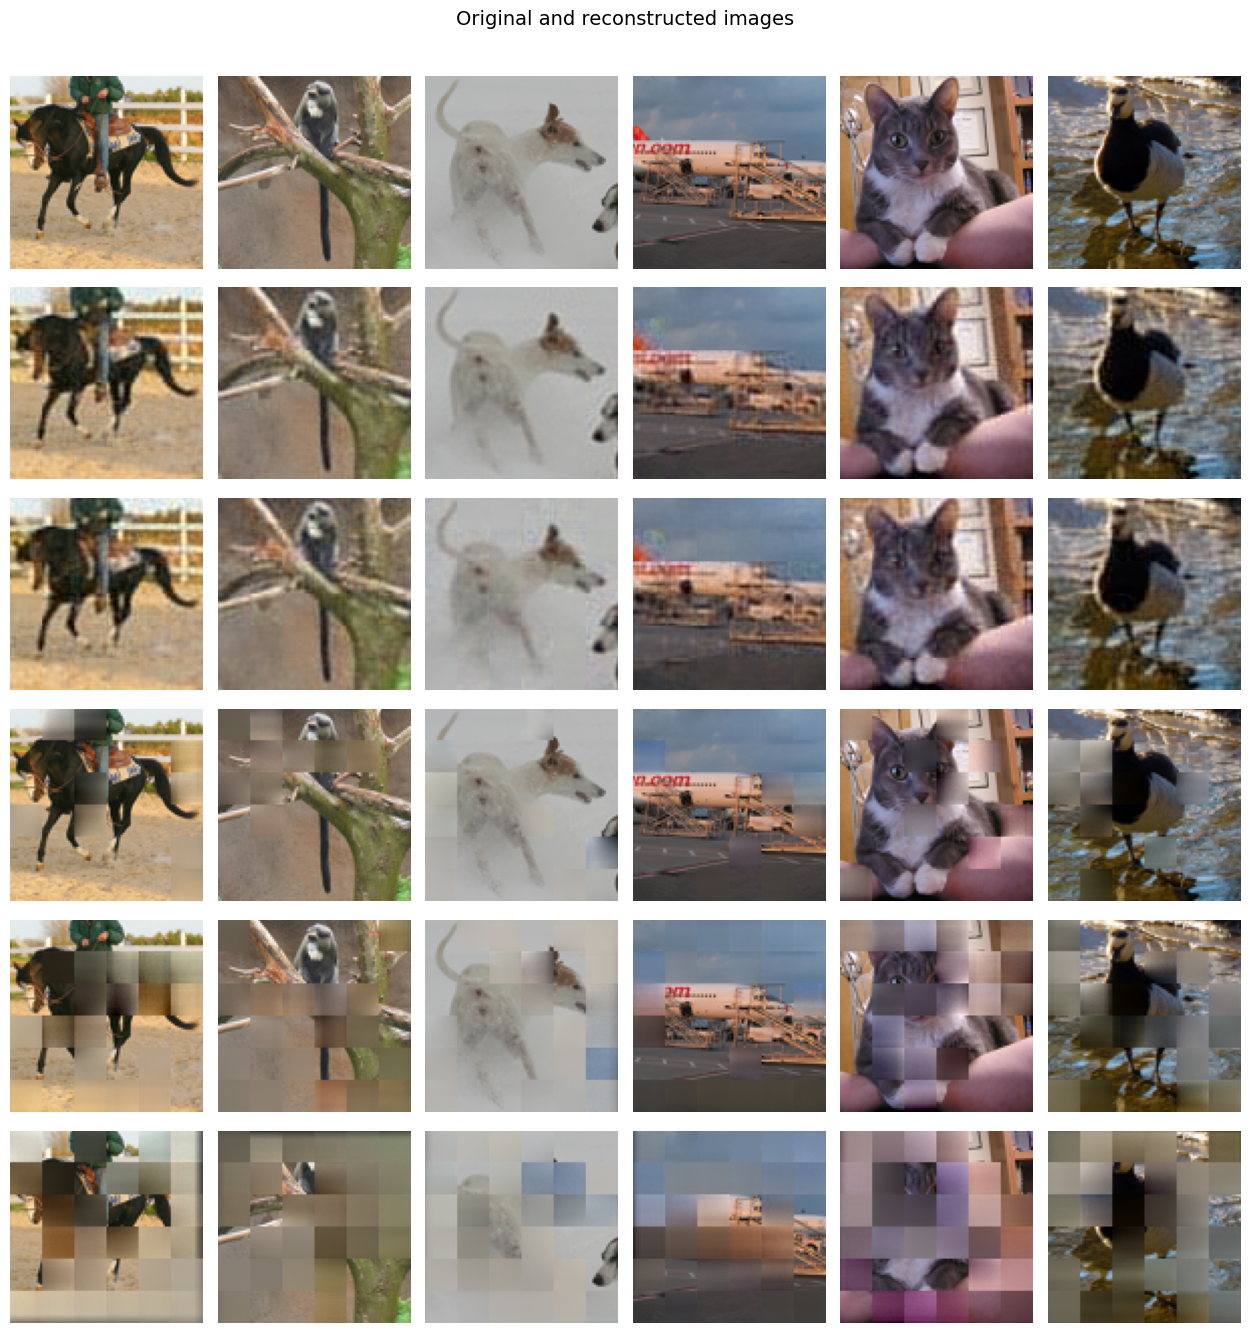

Saved: /kaggle/working/mae_texture_bias/figures/reconstruction_grid.png


In [ ]:
@torch.no_grad()
def visualise_reconstructions(models: Dict[str, nn.Module], loader: DataLoader, n: int = 6) -> None:
    imgs, _ = next(iter(loader))
    imgs = imgs[:n].to(DEVICE)

    rows = ["Original"] + list(models.keys())
    fig, axes = plt.subplots(len(rows), n, figsize=(2.1 * n, 2.2 * len(rows)))

    original = denormalise_batch(imgs).cpu()
    for j in range(n):
        axes[0, j].imshow(original[j].permute(1, 2, 0))
        axes[0, j].axis("off")
        if j == 0:
            axes[0, j].set_ylabel("Original", fontsize=11)

    for i, (name, model) in enumerate(models.items(), start=1):
        model.eval()
        model.to(DEVICE)
        rec = model.reconstruct(imgs)
        rec = denormalise_batch(rec).cpu()

        for j in range(n):
            axes[i, j].imshow(rec[j].permute(1, 2, 0))
            axes[i, j].axis("off")
            if j == 0:
                axes[i, j].set_ylabel(name, fontsize=11)

    plt.suptitle("Original and reconstructed images", y=1.01, fontsize=14)
    plt.tight_layout()
    path = FIG_DIR / "reconstruction_grid.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


visualise_reconstructions(trained_models, probe_test_loader, n=6)

## 12. Embedding extraction

This cell extracts feature embeddings from the trained encoders. These embeddings are used later to test representation quality.

In [ ]:
@torch.no_grad()
def extract_embeddings(model: nn.Module, loader: DataLoader) -> Tuple[np.ndarray, np.ndarray]:
    model.eval()
    model.to(DEVICE)

    all_z = []
    all_y = []

    for imgs, labels in tqdm(loader, desc="extract", leave=False):
        imgs = imgs.to(DEVICE, non_blocking=True)
        z = model.encode(imgs)
        all_z.append(z.detach().cpu())
        all_y.append(labels.detach().cpu())

    Z = torch.cat(all_z, dim=0).numpy()
    y = torch.cat(all_y, dim=0).numpy()

    # Keep only one model on the GPU at a time; this avoids OOM when many baselines are evaluated.
    model.cpu()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return Z, y


def fit_linear_probe(X_train: np.ndarray, y_train: np.ndarray, seed: int, cfg: ExperimentConfig):
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=cfg.linear_probe_max_iter,
            C=1.0,
            solver="lbfgs",
            n_jobs=-1,
            random_state=seed,
        ),
    )
    clf.fit(X_train, y_train)
    return clf


def evaluate_classifier(clf, X: np.ndarray, y: np.ndarray) -> float:
    pred = clf.predict(X)
    return 100.0 * accuracy_score(y, pred)


def evaluate_clean_transfer(models: Dict[str, nn.Module], train_loader: DataLoader, test_loader: DataLoader, cfg: ExperimentConfig):
    embedding_cache = {}
    rows = []

    for name, model in models.items():
        print(f"\nExtracting clean embeddings: {name}")
        X_train, y_train = extract_embeddings(model, train_loader)
        X_test, y_test = extract_embeddings(model, test_loader)
        embedding_cache[name] = {
            "X_train": X_train,
            "y_train": y_train,
            "X_test_clean": X_test,
            "y_test": y_test,
        }

        accs = []
        for s in cfg.probe_seeds:
            clf = fit_linear_probe(X_train, y_train, seed=s, cfg=cfg)
            accs.append(evaluate_classifier(clf, X_test, y_test))

        knn = make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=cfg.knn_k, metric="cosine", n_jobs=-1)
        )
        knn.fit(X_train, y_train)
        knn_acc = evaluate_classifier(knn, X_test, y_test)

        rows.append({
            "model": name,
            "linear_acc_mean": float(np.mean(accs)),
            "linear_acc_std": float(np.std(accs, ddof=1)) if len(accs) > 1 else 0.0,
            "knn_acc": float(knn_acc),
        })

        print(f"{name:14s} | linear={np.mean(accs):.2f}±{np.std(accs):.2f} | kNN={knn_acc:.2f}")

    clean_df = pd.DataFrame(rows).sort_values("linear_acc_mean", ascending=False).reset_index(drop=True)
    return clean_df, embedding_cache


clean_results, embedding_cache = evaluate_clean_transfer(trained_models, probe_train_loader, probe_test_loader, CFG)

display(clean_results)
clean_results.to_csv(TABLE_DIR / "clean_transfer_results.csv", index=False)


Extracting clean embeddings: AE


extract:   0%|          | 0/40 [00:00<?, ?it/s]

extract:   0%|          | 0/63 [00:00<?, ?it/s]

AE             | linear=35.34±0.00 | kNN=26.97

Extracting clean embeddings: DAE_noise0.25


extract:   0%|          | 0/40 [00:00<?, ?it/s]

extract:   0%|          | 0/63 [00:00<?, ?it/s]

... (7 outputs left out)

extract:   0%|          | 0/40 [00:00<?, ?it/s]

extract:   0%|          | 0/63 [00:00<?, ?it/s]

MAE_75         | linear=48.54±0.00 | kNN=38.71


,model,linear_acc_mean,linear_acc_std,knn_acc
0,MAE_75,48.5375,0.000000e+00,38.7125
1,MAE_50,47.0750,8.702336e-15,37.2625
2,MAE_25,43.2875,0.000000e+00,35.2125
3,DAE_noise0.25,38.7125,0.000000e+00,28.3500
4,AE,35.3375,0.000000e+00,26.9750


## 13. Clean transfer visualisation

This cell plots the clean classification results. It helps compare how useful each model’s learned representations are without perturbations.

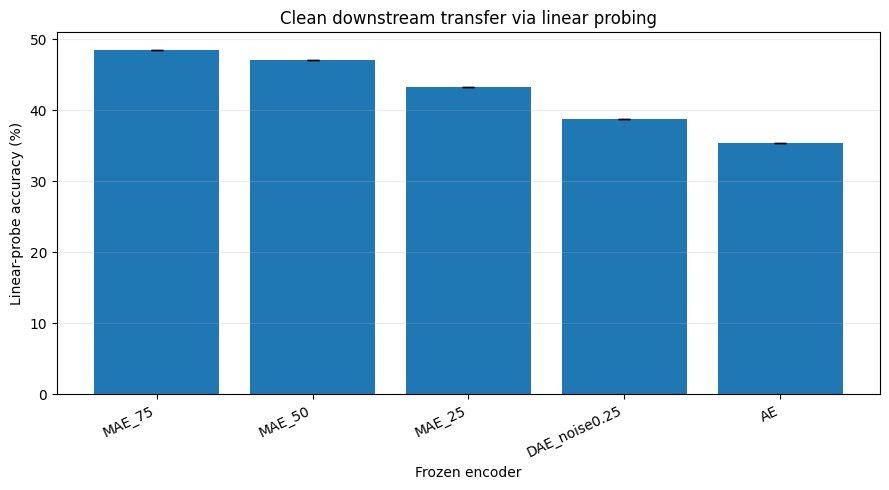

Saved: /kaggle/working/mae_texture_bias/figures/clean_linear_probe_accuracy.png


In [ ]:
def plot_clean_results(df: pd.DataFrame) -> None:
    order = df.sort_values("linear_acc_mean", ascending=False)
    plt.figure(figsize=(9, 5))
    plt.bar(order["model"], order["linear_acc_mean"], yerr=order["linear_acc_std"], capsize=4)
    plt.ylabel("Linear-probe accuracy (%)")
    plt.xlabel("Frozen encoder")
    plt.title("Clean downstream transfer via linear probing")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    path = FIG_DIR / "clean_linear_probe_accuracy.png"
    plt.savefig(path, dpi=200)
    plt.show()
    print("Saved:", path)


plot_clean_results(clean_results)

## 14. Fourier and texture perturbation probes

This is the main mechanism-level part of the project.

### Low-pass filtering
Removes high-frequency detail and preserves broad structure. If a model remains relatively accurate under low-pass filtering, this suggests it can use coarser/global information.

### High-pass filtering
Removes low-frequency structure and keeps fine edges/detail. High retention under high-pass-only images can indicate reliance on local edges or texture-like cues, though it is not a perfect proxy.

### Local pixel shuffle
Shuffles pixels inside small local blocks. This disrupts local texture while preserving coarse block-level colour and some global layout.

### Gaussian blur
A simpler perturbation that suppresses high-frequency detail.

These probes are not definitive proofs of shape bias. They are controlled diagnostic tests that, together with transfer results, support or weaken the masking-reduces-texture-dependence hypothesis.

In [ ]:
def denorm_single(x: torch.Tensor) -> torch.Tensor:
    return (x * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1)


def norm_single(x: torch.Tensor) -> torch.Tensor:
    return (x - IMAGENET_MEAN) / IMAGENET_STD


def fourier_filter_single(x_norm: torch.Tensor, mode: str, cutoff: float) -> torch.Tensor:
    """
    Apply circular Fourier low-pass or high-pass filtering to one normalised image tensor.

    cutoff is expressed as a fraction of the maximum frequency radius.
    """
    x = denorm_single(x_norm).float()
    C, H, W = x.shape

    fy = torch.arange(H, dtype=torch.float32) - H // 2
    fx = torch.arange(W, dtype=torch.float32) - W // 2
    yy, xx = torch.meshgrid(fy, fx, indexing="ij")
    radius = torch.sqrt(xx ** 2 + yy ** 2)
    max_radius = radius.max().clamp_min(1.0)
    threshold = cutoff * max_radius

    if mode == "lowpass":
        mask = (radius <= threshold).float()
    elif mode == "highpass":
        mask = (radius >= threshold).float()
    else:
        raise ValueError("mode must be 'lowpass' or 'highpass'")

    mask = mask.to(x.device).unsqueeze(0)

    fft = torch.fft.fft2(x, dim=(-2, -1))
    fft = torch.fft.fftshift(fft, dim=(-2, -1))
    filtered = fft * mask
    filtered = torch.fft.ifftshift(filtered, dim=(-2, -1))
    recon = torch.fft.ifft2(filtered, dim=(-2, -1)).real
    recon = recon.clamp(0, 1)

    return norm_single(recon)


def local_pixel_shuffle_single(x_norm: torch.Tensor, block_size: int, seed: int) -> torch.Tensor:
    """
    Shuffle pixels inside each local block using the same permutation across channels.
    This disrupts local texture while preserving coarse image layout.
    """
    x = denorm_single(x_norm).float().clone()
    C, H, W = x.shape
    g = torch.Generator()
    g.manual_seed(seed)

    for y in range(0, H, block_size):
        for z in range(0, W, block_size):
            block = x[:, y:min(y + block_size, H), z:min(z + block_size, W)]
            _, bh, bw = block.shape
            flat = block.reshape(C, bh * bw)
            perm = torch.randperm(bh * bw, generator=g)
            block_shuffled = flat[:, perm].reshape(C, bh, bw)
            x[:, y:min(y + block_size, H), z:min(z + block_size, W)] = block_shuffled

    return norm_single(x.clamp(0, 1))


def blur_single(x_norm: torch.Tensor, kernel_size: int, sigma: float) -> torch.Tensor:
    x = denorm_single(x_norm).float()
    if kernel_size % 2 == 0:
        kernel_size += 1
    x = TF.gaussian_blur(x, kernel_size=[kernel_size, kernel_size], sigma=[sigma, sigma])
    return norm_single(x.clamp(0, 1))


class PerturbedDataset(Dataset):
    def __init__(self, base: Dataset, perturbation: str, cfg: ExperimentConfig,
                 mode: Optional[str] = None, cutoff: Optional[float] = None):
        self.base = base
        self.perturbation = perturbation
        self.cfg = cfg
        self.mode = mode
        self.cutoff = cutoff

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx: int):
        x, y = self.base[idx]

        if self.perturbation == "clean":
            return x, y

        if self.perturbation == "fourier":
            assert self.mode in ["lowpass", "highpass"]
            assert self.cutoff is not None
            x = fourier_filter_single(x, mode=self.mode, cutoff=self.cutoff)

        elif self.perturbation == "local_shuffle":
            x = local_pixel_shuffle_single(x, block_size=self.cfg.local_shuffle_block_size, seed=self.cfg.seed + idx)

        elif self.perturbation == "blur":
            x = blur_single(x, kernel_size=self.cfg.blur_kernel_size, sigma=self.cfg.blur_sigma)

        else:
            raise ValueError(f"Unknown perturbation: {self.perturbation}")

        return x, y


def make_perturbed_loader(base_test_dataset: Dataset, cfg: ExperimentConfig,
                          perturbation: str, mode: Optional[str] = None,
                          cutoff: Optional[float] = None) -> DataLoader:
    ds = PerturbedDataset(base_test_dataset, perturbation=perturbation, cfg=cfg, mode=mode, cutoff=cutoff)
    return DataLoader(ds, batch_size=cfg.batch_size, shuffle=False,
                      num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())


# Recover base deterministic test dataset from the existing loader.
BASE_TEST_DATASET = probe_test_loader.dataset

## 15. Visualise perturbations

This cell shows examples of the perturbed images. This helps confirm that the perturbations are being applied correctly.

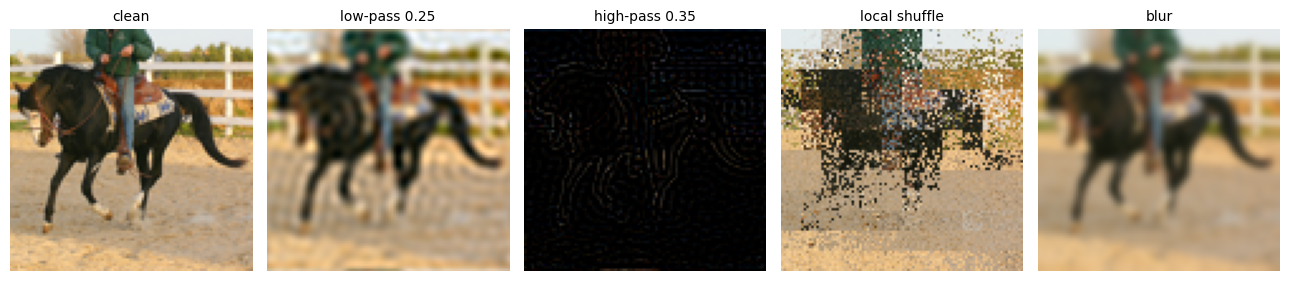

Saved: /kaggle/working/mae_texture_bias/figures/perturbation_examples.png


In [ ]:
def show_perturbation_examples(base_dataset: Dataset, cfg: ExperimentConfig, idx: int = 0) -> None:
    x, y = base_dataset[idx]
    examples = {
        "clean": x,
        f"low-pass {cfg.primary_lowpass_cutoff}": fourier_filter_single(x, "lowpass", cfg.primary_lowpass_cutoff),
        f"high-pass {cfg.primary_highpass_cutoff}": fourier_filter_single(x, "highpass", cfg.primary_highpass_cutoff),
        "local shuffle": local_pixel_shuffle_single(x, cfg.local_shuffle_block_size, cfg.seed + idx),
        "blur": blur_single(x, cfg.blur_kernel_size, cfg.blur_sigma),
    }

    plt.figure(figsize=(13, 3))
    for i, (title, img_norm) in enumerate(examples.items(), start=1):
        plt.subplot(1, len(examples), i)
        img = denorm_single(img_norm).permute(1, 2, 0).cpu().numpy()
        plt.imshow(img)
        plt.title(title, fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    path = FIG_DIR / "perturbation_examples.png"
    plt.savefig(path, dpi=200)
    plt.show()
    print("Saved:", path)


show_perturbation_examples(BASE_TEST_DATASET, CFG, idx=0)

## 16. Evaluate models under Fourier and texture perturbations

This cell evaluates each model on the perturbed datasets. The goal is to measure how robust each representation is when image frequency or texture information is changed.

In [ ]:
def evaluate_on_loader_with_existing_probe(model: nn.Module, clf, loader: DataLoader) -> float:
    X, y = extract_embeddings(model, loader)
    return evaluate_classifier(clf, X, y)


def evaluate_perturbation_suite(models: Dict[str, nn.Module],
                                embedding_cache: Dict[str, Dict[str, np.ndarray]],
                                base_test_dataset: Dataset,
                                cfg: ExperimentConfig) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    For each model:
    - train linear probes on clean train embeddings;
    - evaluate each probe on clean, Fourier, blur, and local-shuffle test embeddings;
    - average across probe seeds.

    Returns:
    - summary_df: paper-ready primary metrics.
    - curve_df: long-format Fourier sensitivity curves.
    """
    summary_rows = []
    curve_rows = []

    # Prebuild perturbed loaders so each model sees exactly the same test transformations.
    lowpass_loaders = {
        c: make_perturbed_loader(base_test_dataset, cfg, perturbation="fourier", mode="lowpass", cutoff=c)
        for c in cfg.fourier_cutoffs
    }
    highpass_loaders = {
        c: make_perturbed_loader(base_test_dataset, cfg, perturbation="fourier", mode="highpass", cutoff=c)
        for c in cfg.fourier_cutoffs
    }
    local_shuffle_loader = make_perturbed_loader(base_test_dataset, cfg, perturbation="local_shuffle")
    blur_loader = make_perturbed_loader(base_test_dataset, cfg, perturbation="blur")

    for name, model in models.items():
        print(f"\nPerturbation evaluation: {name}")
        cache = embedding_cache[name]
        X_train = cache["X_train"]
        y_train = cache["y_train"]
        X_clean = cache["X_test_clean"]
        y_test = cache["y_test"]

        # Extract perturbed embeddings once per model.
        perturbed_embeddings = {"clean": (X_clean, y_test)}

        for c, loader in lowpass_loaders.items():
            print(f"  extracting lowpass cutoff={c}")
            X, y = extract_embeddings(model, loader)
            perturbed_embeddings[f"lowpass_{c:.2f}"] = (X, y)

        for c, loader in highpass_loaders.items():
            print(f"  extracting highpass cutoff={c}")
            X, y = extract_embeddings(model, loader)
            perturbed_embeddings[f"highpass_{c:.2f}"] = (X, y)

        print("  extracting local shuffle")
        X, y = extract_embeddings(model, local_shuffle_loader)
        perturbed_embeddings["local_shuffle"] = (X, y)

        print("  extracting blur")
        X, y = extract_embeddings(model, blur_loader)
        perturbed_embeddings["blur"] = (X, y)

        seed_metric_rows = []

        for s in cfg.probe_seeds:
            clf = fit_linear_probe(X_train, y_train, seed=s, cfg=cfg)

            seed_metrics = {"model": name, "probe_seed": s}
            for metric_name, (X_eval, y_eval) in perturbed_embeddings.items():
                seed_metrics[metric_name] = evaluate_classifier(clf, X_eval, y_eval)
            seed_metric_rows.append(seed_metrics)

        seed_df = pd.DataFrame(seed_metric_rows)

        clean_mean = seed_df["clean"].mean()
        primary_low = f"lowpass_{cfg.primary_lowpass_cutoff:.2f}"
        primary_high = f"highpass_{cfg.primary_highpass_cutoff:.2f}"

        row = {
            "model": name,
            "clean_acc": clean_mean,
            "clean_std": seed_df["clean"].std(ddof=1) if len(seed_df) > 1 else 0.0,
            "primary_lowpass_acc": seed_df[primary_low].mean(),
            "primary_highpass_acc": seed_df[primary_high].mean(),
            "local_shuffle_acc": seed_df["local_shuffle"].mean(),
            "blur_acc": seed_df["blur"].mean(),
        }
        row["lowpass_drop"] = row["clean_acc"] - row["primary_lowpass_acc"]
        row["highpass_retention"] = row["primary_highpass_acc"] / max(row["clean_acc"], 1e-9)
        row["local_shuffle_drop"] = row["clean_acc"] - row["local_shuffle_acc"]
        row["blur_drop"] = row["clean_acc"] - row["blur_acc"]
        summary_rows.append(row)

        # Fourier curve rows
        for c in cfg.fourier_cutoffs:
            curve_rows.append({
                "model": name,
                "filter": "lowpass",
                "cutoff": c,
                "accuracy": seed_df[f"lowpass_{c:.2f}"].mean(),
                "std": seed_df[f"lowpass_{c:.2f}"].std(ddof=1) if len(seed_df) > 1 else 0.0,
            })
            curve_rows.append({
                "model": name,
                "filter": "highpass",
                "cutoff": c,
                "accuracy": seed_df[f"highpass_{c:.2f}"].mean(),
                "std": seed_df[f"highpass_{c:.2f}"].std(ddof=1) if len(seed_df) > 1 else 0.0,
            })

    summary_df = pd.DataFrame(summary_rows).sort_values("clean_acc", ascending=False).reset_index(drop=True)
    curve_df = pd.DataFrame(curve_rows)
    return summary_df, curve_df


perturbation_summary, fourier_curves = evaluate_perturbation_suite(
    trained_models, embedding_cache, BASE_TEST_DATASET, CFG
)

display(perturbation_summary)
display(fourier_curves.head())

perturbation_summary.to_csv(TABLE_DIR / "perturbation_summary.csv", index=False)
fourier_curves.to_csv(TABLE_DIR / "fourier_curves.csv", index=False)


Perturbation evaluation: AE
  extracting lowpass cutoff=0.15


extract:   0%|          | 0/63 [00:00<?, ?it/s]

  extracting lowpass cutoff=0.25


extract:   0%|          | 0/63 [00:00<?, ?it/s]

  extracting lowpass cutoff=0.35


extract:   0%|          | 0/63 [00:00<?, ?it/s]

... (92 outputs left out)

  extracting blur


extract:   0%|          | 0/63 [00:00<?, ?it/s]

,model,clean_acc,clean_std,primary_lowpass_acc,primary_highpass_acc,local_shuffle_acc,blur_acc,lowpass_drop,highpass_retention,local_shuffle_drop,blur_drop
0,MAE_75,48.5375,0.000000e+00,47.9500,10.20,41.5250,45.9000,0.5875,0.210147,7.0125,2.6375
1,MAE_50,47.0750,8.702336e-15,46.4750,10.00,37.6500,44.0500,0.6000,0.212427,9.4250,3.0250
2,MAE_25,43.2875,0.000000e+00,43.4750,10.00,35.5875,41.2500,-0.1875,0.231014,7.7000,2.0375
3,DAE_noise0.25,38.7125,0.000000e+00,39.7125,11.35,26.5750,38.1375,-1.0000,0.293187,12.1375,0.5750
4,AE,35.3375,0.000000e+00,36.8000,10.60,23.6375,36.3375,-1.4625,0.299965,11.7000,-1.0000


,model,filter,cutoff,accuracy,std
0,AE,lowpass,0.15,35.200,0.000000e+00
1,AE,highpass,0.15,14.025,2.175584e-15
2,AE,lowpass,0.25,36.800,0.000000e+00
3,AE,highpass,0.25,11.875,0.000000e+00
4,AE,lowpass,0.35,36.025,0.000000e+00


## 17. Plot Fourier sensitivity and texture perturbation results

This cell plots the perturbation results so the robustness patterns are easier to compare across AE, DAE, and MAE.

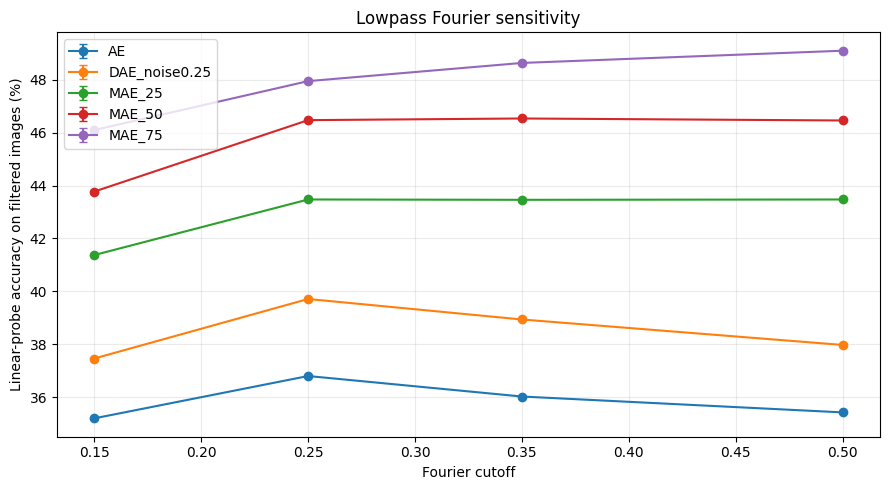

Saved: /kaggle/working/mae_texture_bias/figures/fourier_lowpass_sensitivity.png


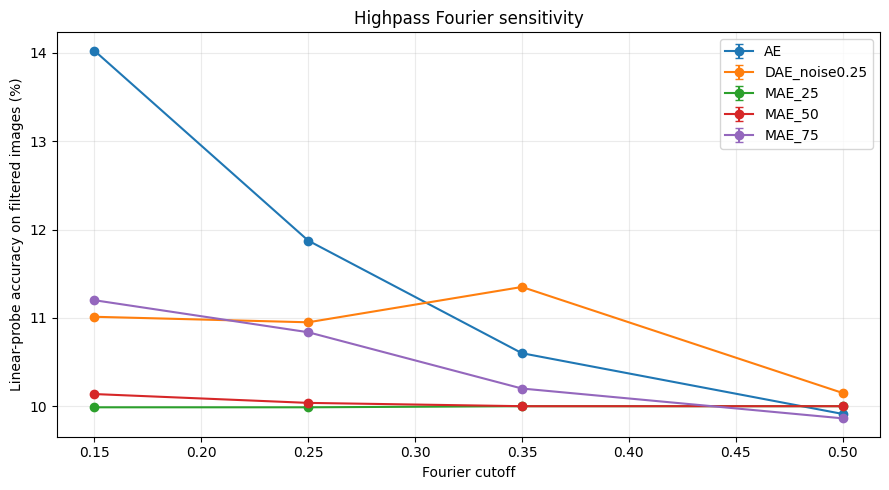

Saved: /kaggle/working/mae_texture_bias/figures/fourier_highpass_sensitivity.png


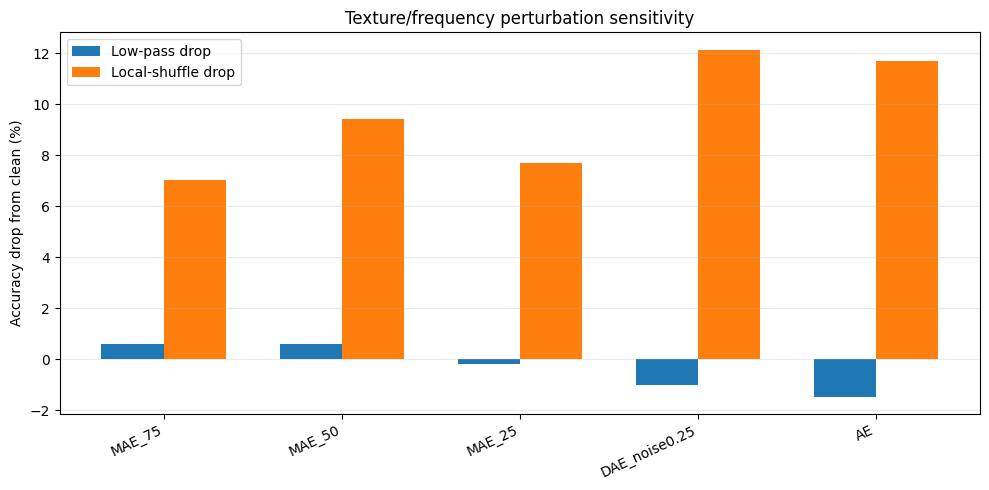

Saved: /kaggle/working/mae_texture_bias/figures/texture_frequency_drops.png


In [ ]:
def plot_fourier_curves(curve_df: pd.DataFrame) -> None:
    for filter_name in ["lowpass", "highpass"]:
        sub = curve_df[curve_df["filter"] == filter_name]
        plt.figure(figsize=(9, 5))
        for model_name in sub["model"].unique():
            m = sub[sub["model"] == model_name].sort_values("cutoff")
            plt.errorbar(m["cutoff"], m["accuracy"], yerr=m["std"], marker="o", capsize=3, label=model_name)
        plt.xlabel("Fourier cutoff")
        plt.ylabel("Linear-probe accuracy on filtered images (%)")
        plt.title(f"{filter_name.capitalize()} Fourier sensitivity")
        plt.grid(alpha=0.25)
        plt.legend()
        plt.tight_layout()
        path = FIG_DIR / f"fourier_{filter_name}_sensitivity.png"
        plt.savefig(path, dpi=200)
        plt.show()
        print("Saved:", path)


def plot_texture_drops(summary_df: pd.DataFrame) -> None:
    df = summary_df.copy()
    x = np.arange(len(df))
    width = 0.35

    plt.figure(figsize=(10, 5))
    plt.bar(x - width/2, df["lowpass_drop"], width, label="Low-pass drop")
    plt.bar(x + width/2, df["local_shuffle_drop"], width, label="Local-shuffle drop")
    plt.xticks(x, df["model"], rotation=25, ha="right")
    plt.ylabel("Accuracy drop from clean (%)")
    plt.title("Texture/frequency perturbation sensitivity")
    plt.grid(axis="y", alpha=0.25)
    plt.legend()
    plt.tight_layout()
    path = FIG_DIR / "texture_frequency_drops.png"
    plt.savefig(path, dpi=200)
    plt.show()
    print("Saved:", path)


plot_fourier_curves(fourier_curves)
plot_texture_drops(perturbation_summary)

## 18. Cue-conflict hybrid-image probe

This cell creates hybrid images to test what visual information each model relies on.

Each hybrid image mixes two different images:

- the low-frequency part from image A, which represents the broad shape;
- the high-frequency part from image B, which represents fine texture or detail.

The trained probe then predicts the class of the hybrid image. We check whether the model follows the shape label, the texture/detail label, or neither.

This helps test whether the model depends more on global structure or local texture.

In [ ]:
def _fourier_component_01(x01: torch.Tensor, mode: str, cutoff: float) -> torch.Tensor:
    """Return an unclipped Fourier component in pixel space [approximately].

    x01 is expected to be a single image in [0, 1] with shape C,H,W.
    For high-pass we intentionally keep the signed residual rather than clamping;
    this allows low-frequency structure from one image and high-frequency detail
    from another image to be additively combined.
    """
    C, H, W = x01.shape
    yy, xx = torch.meshgrid(torch.arange(H), torch.arange(W), indexing="ij")
    yy = yy - H // 2
    xx = xx - W // 2
    rr = torch.sqrt(xx.float() ** 2 + yy.float() ** 2)
    radius = cutoff * min(H, W)
    if mode == "lowpass":
        mask = (rr <= radius).float()
    elif mode == "highpass":
        mask = (rr >= radius).float()
    else:
        raise ValueError("mode must be 'lowpass' or 'highpass'")
    mask = mask.to(x01.device).unsqueeze(0)
    fft = torch.fft.fft2(x01, dim=(-2, -1))
    fft = torch.fft.fftshift(fft, dim=(-2, -1))
    filtered = fft * mask
    filtered = torch.fft.ifftshift(filtered, dim=(-2, -1))
    return torch.fft.ifft2(filtered, dim=(-2, -1)).real


def make_hybrid_cue_image(x_shape_norm: torch.Tensor, x_texture_norm: torch.Tensor, cfg: ExperimentConfig) -> torch.Tensor:
    """Combine coarse structure from x_shape with high-frequency detail from x_texture."""
    shape01 = denorm_single(x_shape_norm).float()
    texture01 = denorm_single(x_texture_norm).float()
    low = _fourier_component_01(shape01, mode="lowpass", cutoff=cfg.hybrid_shape_cutoff)
    high = _fourier_component_01(texture01, mode="highpass", cutoff=cfg.hybrid_texture_cutoff)
    hybrid01 = (low + high).clamp(0, 1)
    return norm_single(hybrid01)


def dataset_labels(base_dataset: Dataset) -> np.ndarray:
    """Robustly extract labels from a torchvision dataset or Subset wrapper."""
    labels = []
    for i in range(len(base_dataset)):
        _, y = base_dataset[i]
        labels.append(int(y))
    return np.asarray(labels)


class HybridCueConflictDataset(Dataset):
    def __init__(self, base: Dataset, cfg: ExperimentConfig, max_samples: Optional[int] = None):
        self.base = base
        self.cfg = cfg
        labels = dataset_labels(base)
        rng = np.random.default_rng(cfg.seed + 9001)
        n = len(base) if max_samples is None else min(max_samples, len(base))
        anchors = rng.choice(len(base), size=n, replace=False)
        pairs = []
        for i in anchors:
            yi = labels[i]
            candidates = np.flatnonzero(labels != yi)
            j = int(rng.choice(candidates))
            pairs.append((int(i), j, int(yi), int(labels[j])))
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx: int):
        i, j, y_shape, y_texture = self.pairs[idx]
        x_shape, _ = self.base[i]
        x_texture, _ = self.base[j]
        x = make_hybrid_cue_image(x_shape, x_texture, self.cfg)
        return x, torch.tensor(y_shape, dtype=torch.long), torch.tensor(y_texture, dtype=torch.long)


@torch.no_grad()
def extract_hybrid_embeddings(model: nn.Module, loader: DataLoader) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    model.to(DEVICE)
    all_z, all_y_shape, all_y_texture = [], [], []
    for imgs, y_shape, y_texture in tqdm(loader, desc="hybrid extract", leave=False):
        imgs = imgs.to(DEVICE, non_blocking=True)
        z = model.encode(imgs)
        all_z.append(z.detach().cpu())
        all_y_shape.append(y_shape.detach().cpu())
        all_y_texture.append(y_texture.detach().cpu())
    model.cpu()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return (
        torch.cat(all_z).numpy(),
        torch.cat(all_y_shape).numpy(),
        torch.cat(all_y_texture).numpy(),
    )


def evaluate_hybrid_cue_conflict(models: Dict[str, nn.Module],
                                 embedding_cache: Dict[str, Dict[str, np.ndarray]],
                                 base_test_dataset: Dataset,
                                 cfg: ExperimentConfig) -> pd.DataFrame:
    hybrid_ds = HybridCueConflictDataset(base_test_dataset, cfg, max_samples=cfg.hybrid_cue_max_samples)
    hybrid_loader = DataLoader(hybrid_ds, batch_size=cfg.batch_size, shuffle=False,
                               num_workers=cfg.num_workers, pin_memory=torch.cuda.is_available())
    rows = []
    for name, model in models.items():
        print(f"\nHybrid cue-conflict evaluation: {name}")
        cache = embedding_cache[name]
        X_train, y_train = cache["X_train"], cache["y_train"]
        clf = fit_linear_probe(X_train, y_train, seed=cfg.canonical_probe_seed, cfg=cfg)
        X_h, y_shape, y_texture = extract_hybrid_embeddings(model, hybrid_loader)
        pred = clf.predict(X_h)
        shape_agree = 100.0 * np.mean(pred == y_shape)
        texture_agree = 100.0 * np.mean(pred == y_texture)
        other = 100.0 * np.mean((pred != y_shape) & (pred != y_texture))
        rows.append({
            "model": name,
            "n_hybrid": len(y_shape),
            "shape_lowfreq_agreement": float(shape_agree),
            "texture_highfreq_agreement": float(texture_agree),
            "other_prediction_rate": float(other),
            "shape_minus_texture": float(shape_agree - texture_agree),
        })
        print(f"{name:14s} | shape={shape_agree:.2f}% | texture={texture_agree:.2f}% | other={other:.2f}%")
    return pd.DataFrame(rows).sort_values("shape_minus_texture", ascending=False).reset_index(drop=True)


hybrid_cue_df = evaluate_hybrid_cue_conflict(trained_models, embedding_cache, BASE_TEST_DATASET, CFG)
display(hybrid_cue_df)
hybrid_cue_df.to_csv(TABLE_DIR / "hybrid_cue_conflict_results.csv", index=False)



Hybrid cue-conflict evaluation: AE


hybrid extract:   0%|          | 0/8 [00:00<?, ?it/s]

AE             | shape=33.20% | texture=6.90% | other=59.90%

Hybrid cue-conflict evaluation: DAE_noise0.25


hybrid extract:   0%|          | 0/8 [00:00<?, ?it/s]

DAE_noise0.25  | shape=36.80% | texture=6.60% | other=56.60%

Hybrid cue-conflict evaluation: MAE_25


hybrid extract:   0%|          | 0/8 [00:00<?, ?it/s]

... (2 outputs left out)

MAE_50         | shape=43.90% | texture=6.30% | other=49.80%

Hybrid cue-conflict evaluation: MAE_75


hybrid extract:   0%|          | 0/8 [00:00<?, ?it/s]

MAE_75         | shape=46.00% | texture=5.50% | other=48.50%


,model,n_hybrid,shape_lowfreq_agreement,texture_highfreq_agreement,other_prediction_rate,shape_minus_texture
0,MAE_75,1000,46.0,5.5,48.5,40.5
1,MAE_50,1000,43.9,6.3,49.8,37.6
2,MAE_25,1000,42.1,6.5,51.4,35.6
3,DAE_noise0.25,1000,36.8,6.6,56.6,30.2
4,AE,1000,33.2,6.9,59.9,26.3


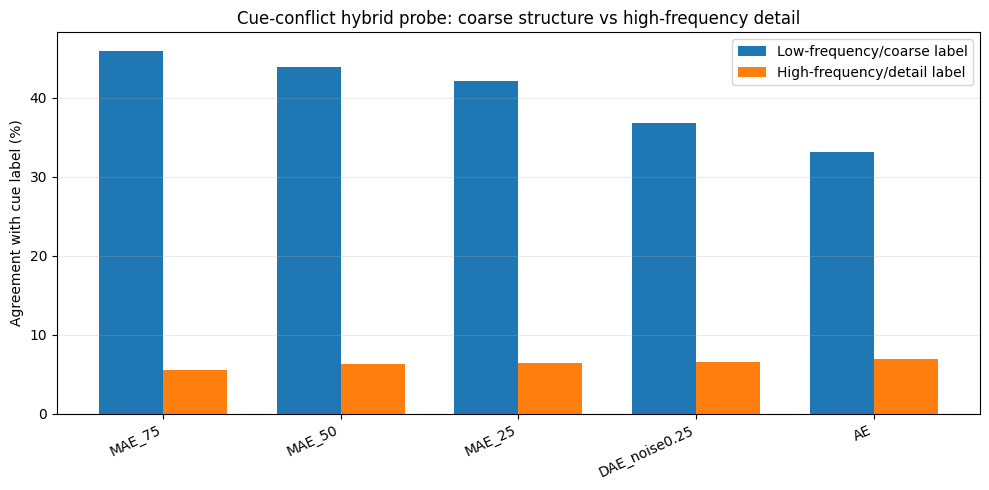

Saved: /kaggle/working/mae_texture_bias/figures/hybrid_cue_conflict_shape_vs_texture.png


In [ ]:

# ==============================================================
# Plot hybrid cue-conflict probe
# ==============================================================

def plot_hybrid_cue_conflict(df: pd.DataFrame) -> None:
    order = df.sort_values("shape_minus_texture", ascending=False).reset_index(drop=True)
    x = np.arange(len(order))
    width = 0.36
    plt.figure(figsize=(10, 5))
    plt.bar(x - width/2, order["shape_lowfreq_agreement"], width, label="Low-frequency/coarse label")
    plt.bar(x + width/2, order["texture_highfreq_agreement"], width, label="High-frequency/detail label")
    plt.xticks(x, order["model"], rotation=25, ha="right")
    plt.ylabel("Agreement with cue label (%)")
    plt.title("Cue-conflict hybrid probe: coarse structure vs high-frequency detail")
    plt.grid(axis="y", alpha=0.25)
    plt.legend()
    plt.tight_layout()
    path = FIG_DIR / "hybrid_cue_conflict_shape_vs_texture.png"
    plt.savefig(path, dpi=200)
    plt.show()
    print("Saved:", path)

plot_hybrid_cue_conflict(hybrid_cue_df)



## 19. Sample-efficiency probe

A representation can be useful even when labelled data is limited. This probe trains the same linear classifier on progressively smaller fractions of the labelled training embeddings. If MAE features are genuinely more transferable, they should remain competitive when the probe has fewer labels.


In [ ]:
def stratified_fraction_indices(y: np.ndarray, fraction: float, seed: int) -> np.ndarray:
    rng = np.random.default_rng(seed)
    idxs = []
    for cls in np.unique(y):
        cls_idx = np.flatnonzero(y == cls)
        k = max(1, int(round(len(cls_idx) * fraction)))
        idxs.extend(rng.choice(cls_idx, size=k, replace=False).tolist())
    rng.shuffle(idxs)
    return np.asarray(idxs, dtype=int)


def evaluate_sample_efficiency(embedding_cache: Dict[str, Dict[str, np.ndarray]], cfg: ExperimentConfig) -> pd.DataFrame:
    rows = []
    for name, cache in embedding_cache.items():
        X_train, y_train = cache["X_train"], cache["y_train"]
        X_test, y_test = cache["X_test_clean"], cache["y_test"]
        for frac in cfg.sample_efficiency_fractions:
            for s in cfg.probe_seeds:
                idx = stratified_fraction_indices(y_train, frac, seed=1000 + s)
                clf = fit_linear_probe(X_train[idx], y_train[idx], seed=s, cfg=cfg)
                acc = evaluate_classifier(clf, X_test, y_test)
                rows.append({
                    "model": name,
                    "fraction": float(frac),
                    "probe_seed": int(s),
                    "n_train": int(len(idx)),
                    "accuracy": float(acc),
                })
    raw = pd.DataFrame(rows)
    summary = raw.groupby(["model", "fraction"], as_index=False).agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else 0.0),
        n_train=("n_train", "mean"),
    )
    raw.to_csv(TABLE_DIR / "sample_efficiency_raw.csv", index=False)
    summary.to_csv(TABLE_DIR / "sample_efficiency_summary.csv", index=False)
    return summary


sample_efficiency_df = evaluate_sample_efficiency(embedding_cache, CFG)
display(sample_efficiency_df)


,model,fraction,accuracy_mean,accuracy_std,n_train
0,AE,0.10,24.787500,0.336108,500.0
1,AE,0.25,29.216667,0.326040,1250.0
2,AE,0.50,32.458333,0.809160,2500.0
3,AE,1.00,35.362500,0.033072,5000.0
4,DAE_noise0.25,0.10,27.820833,0.721363,500.0
5,DAE_noise0.25,0.25,32.429167,0.895853,1250.0
6,DAE_noise0.25,0.50,36.041667,0.200520,2500.0
7,DAE_noise0.25,1.00,38.695833,0.026021,5000.0
8,MAE_25,0.10,33.554167,0.329852,500.0
9,MAE_25,0.25,35.920833,0.899682,1250.0


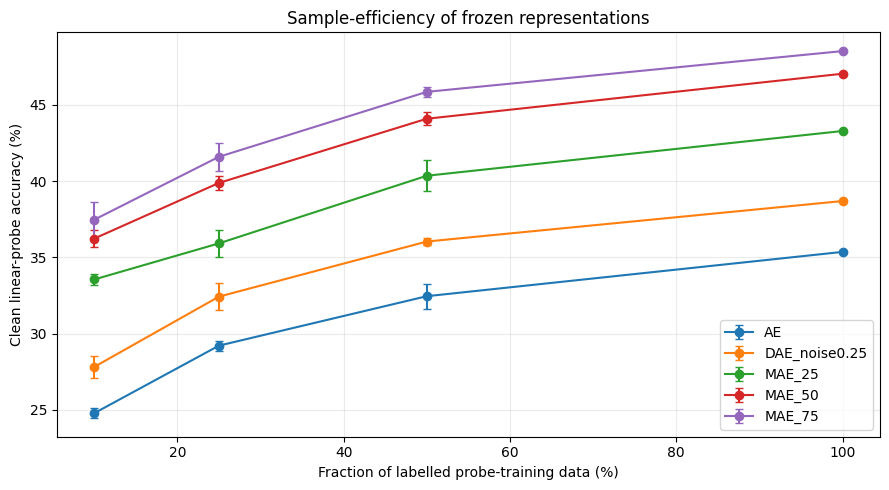

Saved: /kaggle/working/mae_texture_bias/figures/sample_efficiency_curves.png


In [ ]:

# ==============================================================
# Plot sample-efficiency curves
# ==============================================================

def plot_sample_efficiency(df: pd.DataFrame) -> None:
    plt.figure(figsize=(9, 5))
    for name in df["model"].unique():
        sub = df[df["model"] == name].sort_values("fraction")
        plt.errorbar(100 * sub["fraction"], sub["accuracy_mean"], yerr=sub["accuracy_std"],
                     marker="o", capsize=3, label=name)
    plt.xlabel("Fraction of labelled probe-training data (%)")
    plt.ylabel("Clean linear-probe accuracy (%)")
    plt.title("Sample-efficiency of frozen representations")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    path = FIG_DIR / "sample_efficiency_curves.png"
    plt.savefig(path, dpi=200)
    plt.show()
    print("Saved:", path)

plot_sample_efficiency(sample_efficiency_df)



## 20. Paired statistical checks against AE

The clean test set is paired: every model is evaluated on the same images. This section therefore compares each model against the AE baseline using paired correctness vectors.

Reported quantities:

- **accuracy difference** in percentage points;
- **paired bootstrap confidence interval**;
- **McNemar-style exact binomial test** over discordant examples.



In [ ]:
from scipy.stats import binomtest


def paired_bootstrap_ci(diff_values: np.ndarray, n_boot: int, confidence: float, seed: int) -> Tuple[float, float]:
    rng = np.random.default_rng(seed)
    n = len(diff_values)
    means = np.empty(n_boot, dtype=np.float64)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        means[b] = diff_values[idx].mean()
    alpha = 1.0 - confidence
    lo, hi = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return float(100.0 * lo), float(100.0 * hi)


def canonical_predictions_for_model(model_name: str, cache: Dict[str, np.ndarray], cfg: ExperimentConfig) -> np.ndarray:
    clf = fit_linear_probe(cache["X_train"], cache["y_train"], seed=cfg.canonical_probe_seed, cfg=cfg)
    return clf.predict(cache["X_test_clean"])


def paired_model_comparisons(embedding_cache: Dict[str, Dict[str, np.ndarray]], cfg: ExperimentConfig) -> pd.DataFrame:
    if "AE" not in embedding_cache:
        print("AE baseline unavailable; paired comparisons skipped.")
        return pd.DataFrame()
    y = embedding_cache["AE"]["y_test"]
    ae_pred = canonical_predictions_for_model("AE", embedding_cache["AE"], cfg)
    ae_correct = (ae_pred == y)
    rows = []
    for name, cache in embedding_cache.items():
        if name == "AE":
            continue
        pred = canonical_predictions_for_model(name, cache, cfg)
        correct = (pred == y)
        diff_values = correct.astype(float) - ae_correct.astype(float)
        diff_pp = 100.0 * diff_values.mean()
        lo, hi = paired_bootstrap_ci(diff_values, cfg.bootstrap_iterations, cfg.bootstrap_confidence, cfg.seed + 77)
        # Discordant examples for exact McNemar-style paired test.
        better = int(np.sum(correct & ~ae_correct))
        worse = int(np.sum(~correct & ae_correct))
        discordant = better + worse
        if discordant > 0:
            pval = float(binomtest(k=better, n=discordant, p=0.5, alternative="two-sided").pvalue)
        else:
            pval = 1.0
        rows.append({
            "comparison": f"{name} vs AE",
            "model": name,
            "ae_acc": float(100.0 * ae_correct.mean()),
            "model_acc": float(100.0 * correct.mean()),
            "delta_acc_pp": float(diff_pp),
            "bootstrap_ci_low": lo,
            "bootstrap_ci_high": hi,
            "mcnemar_better_cases": better,
            "mcnemar_worse_cases": worse,
            "mcnemar_p_value": pval,
        })
    return pd.DataFrame(rows).sort_values("delta_acc_pp", ascending=False).reset_index(drop=True)


paired_stats_df = paired_model_comparisons(embedding_cache, CFG)
display(paired_stats_df)
paired_stats_df.to_csv(TABLE_DIR / "paired_statistical_comparisons.csv", index=False)


,comparison,model,ae_acc,model_acc,delta_acc_pp,bootstrap_ci_low,bootstrap_ci_high,mcnemar_better_cases,mcnemar_worse_cases,mcnemar_p_value
0,MAE_75 vs AE,MAE_75,35.3375,48.5375,13.2000,11.924688,14.450000,1909,853,6.760946e-92
1,MAE_50 vs AE,MAE_50,35.3375,47.0750,11.7375,10.525000,12.987812,1815,876,1.357928e-74
2,MAE_25 vs AE,MAE_25,35.3375,43.2875,7.9500,6.725000,9.187500,1606,970,2.875345e-36
3,DAE_noise0.25 vs AE,DAE_noise0.25,35.3375,38.7125,3.3750,2.187188,4.525312,1265,995,1.470566e-08



## 21. Linear CKA representation comparison

Accuracy can improve even if two encoders learn very similar feature spaces. Linear CKA provides a representation-level comparison between frozen embeddings. Lower similarity to AE together with better transfer or lower texture sensitivity would support the claim that masking changes the learned representation, not merely the final probe.


,AE,DAE_noise0.25,MAE_25,MAE_50,MAE_75
AE,1.000000,0.381058,0.366893,0.436842,0.481837
DAE_noise0.25,0.381058,1.000000,0.160324,0.219711,0.230559
MAE_25,0.366893,0.160324,1.000000,0.702174,0.718302
MAE_50,0.436842,0.219711,0.702174,1.000000,0.827535
MAE_75,0.481837,0.230559,0.718302,0.827535,1.000000


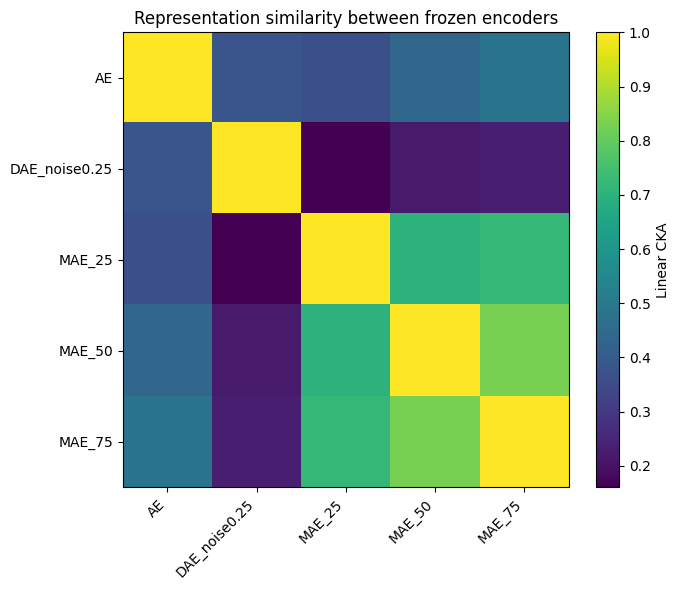

Saved: /kaggle/working/mae_texture_bias/figures/linear_cka_heatmap.png


In [ ]:
def center_columns(X: np.ndarray) -> np.ndarray:
    return X - X.mean(axis=0, keepdims=True)


def linear_cka(X: np.ndarray, Y: np.ndarray) -> float:
    Xc = center_columns(X)
    Yc = center_columns(Y)
    hsic = np.linalg.norm(Xc.T @ Yc, ord="fro") ** 2
    norm_x = np.linalg.norm(Xc.T @ Xc, ord="fro")
    norm_y = np.linalg.norm(Yc.T @ Yc, ord="fro")
    return float(hsic / max(norm_x * norm_y, 1e-12))


def compute_cka_matrix(embedding_cache: Dict[str, Dict[str, np.ndarray]]) -> pd.DataFrame:
    names = list(embedding_cache.keys())
    mat = np.zeros((len(names), len(names)), dtype=float)
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            mat[i, j] = linear_cka(embedding_cache[a]["X_test_clean"], embedding_cache[b]["X_test_clean"])
    return pd.DataFrame(mat, index=names, columns=names)


cka_df = compute_cka_matrix(embedding_cache)
display(cka_df)
cka_df.to_csv(TABLE_DIR / "linear_cka_matrix.csv")

plt.figure(figsize=(7, 6))
plt.imshow(cka_df.values, aspect="auto")
plt.colorbar(label="Linear CKA")
plt.xticks(np.arange(len(cka_df.columns)), cka_df.columns, rotation=45, ha="right")
plt.yticks(np.arange(len(cka_df.index)), cka_df.index)
plt.title("Representation similarity between frozen encoders")
plt.tight_layout()
path = FIG_DIR / "linear_cka_heatmap.png"
plt.savefig(path, dpi=200)
plt.show()
print("Saved:", path)


## 22. Representational Similarity Analysis

RSA compares the geometry of the learned embedding space with an idealised semantic geometry where same-class pairs are close and different-class pairs are far.



In [ ]:
def rsa_score(embeds: np.ndarray, labels: np.ndarray, n_samples: int, seed: int) -> Tuple[float, float]:
    rng = np.random.default_rng(seed)
    n = min(n_samples, len(labels))
    idx = rng.choice(len(labels), size=n, replace=False)

    E = embeds[idx]
    L = labels[idx]

    embed_dist = squareform(pdist(E, metric="cosine"))
    semantic_dist = (L[:, None] != L[None, :]).astype(float)

    tri = np.triu_indices(n, k=1)
    rho, pval = spearmanr(embed_dist[tri], semantic_dist[tri])
    return float(rho), float(pval)


rsa_rows = []
for name, cache in embedding_cache.items():
    rho, pval = rsa_score(cache["X_test_clean"], cache["y_test"], CFG.rsa_samples, CFG.seed)
    rsa_rows.append({"model": name, "rsa_spearman": rho, "rsa_pvalue": pval})
    print(f"{name:14s} | RSA Spearman rho={rho:.4f}, p={pval:.2e}")

rsa_df = pd.DataFrame(rsa_rows).sort_values("rsa_spearman", ascending=False).reset_index(drop=True)
display(rsa_df)
rsa_df.to_csv(TABLE_DIR / "rsa_results.csv", index=False)

AE             | RSA Spearman rho=0.0693, p=9.89e-133
DAE_noise0.25  | RSA Spearman rho=0.0364, p=8.54e-38
MAE_25         | RSA Spearman rho=0.1162, p=0.00e+00
MAE_50         | RSA Spearman rho=0.1551, p=0.00e+00
MAE_75         | RSA Spearman rho=0.1554, p=0.00e+00


,model,rsa_spearman,rsa_pvalue
0,MAE_75,0.155409,0.000000e+00
1,MAE_50,0.155105,0.000000e+00
2,MAE_25,0.116198,0.000000e+00
3,AE,0.069329,9.889324e-133
4,DAE_noise0.25,0.036372,8.538466e-38


## 23. Consolidated paper-ready results

This section merges all main metrics into one table.


In [ ]:
final_results = (
    perturbation_summary
    .merge(clean_results[["model", "knn_acc"]], on="model", how="left")
    .merge(rsa_df[["model", "rsa_spearman"]], on="model", how="left")
)

# Add explicit model family and mask ratio columns for plotting/analysis.
def parse_family(model_name: str) -> str:
    if model_name.startswith("MAE"):
        return "MAE"
    if model_name.startswith("DAE"):
        return "DAE"
    return "AE"

def parse_mask_ratio(model_name: str) -> Optional[float]:
    if model_name.startswith("MAE_"):
        return int(model_name.split("_")[1]) / 100.0
    if model_name == "AE":
        return 0.0
    return np.nan

final_results["family"] = final_results["model"].apply(parse_family)
final_results["mask_ratio"] = final_results["model"].apply(parse_mask_ratio)

display(final_results)

final_results.to_csv(TABLE_DIR / "final_results.csv", index=False)
save_json(final_results.to_dict(orient="records"), OUT / "final_results.json")
print("Saved:", TABLE_DIR / "final_results.csv")
print("Saved:", OUT / "final_results.json")

,model,clean_acc,clean_std,primary_lowpass_acc,primary_highpass_acc,local_shuffle_acc,blur_acc,lowpass_drop,highpass_retention,local_shuffle_drop,blur_drop,knn_acc,rsa_spearman,family,mask_ratio
0,MAE_75,48.5375,0.000000e+00,47.9500,10.20,41.5250,45.9000,0.5875,0.210147,7.0125,2.6375,38.7125,0.155409,MAE,0.75
1,MAE_50,47.0750,8.702336e-15,46.4750,10.00,37.6500,44.0500,0.6000,0.212427,9.4250,3.0250,37.2625,0.155105,MAE,0.50
2,MAE_25,43.2875,0.000000e+00,43.4750,10.00,35.5875,41.2500,-0.1875,0.231014,7.7000,2.0375,35.2125,0.116198,MAE,0.25
3,DAE_noise0.25,38.7125,0.000000e+00,39.7125,11.35,26.5750,38.1375,-1.0000,0.293187,12.1375,0.5750,28.3500,0.036372,DAE,NaN
4,AE,35.3375,0.000000e+00,36.8000,10.60,23.6375,36.3375,-1.4625,0.299965,11.7000,-1.0000,26.9750,0.069329,AE,0.00


Saved: /kaggle/working/mae_texture_bias/tables/final_results.csv
Saved: /kaggle/working/mae_texture_bias/final_results.json



## 24. Reconstruction-transfer trade-off
 This cell compares reconstruction loss with downstream representation quality. This tests whether better reconstruction actually means better learned features.


,model,final_pretrain_loss,clean_acc,lowpass_drop,local_shuffle_drop,rsa_spearman
0,AE,0.082629,35.3375,-1.4625,11.7000,0.069329
1,DAE_noise0.25,0.105592,38.7125,-1.0000,12.1375,0.036372
2,MAE_25,0.496989,43.2875,-0.1875,7.7000,0.116198
3,MAE_50,0.547483,47.0750,0.6000,9.4250,0.155105
4,MAE_75,0.649563,48.5375,0.5875,7.0125,0.155409


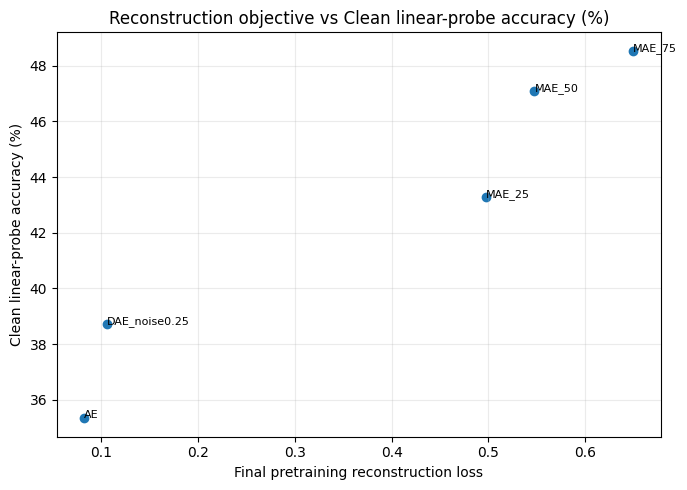

Saved: /kaggle/working/mae_texture_bias/figures/loss_vs_clean_accuracy.png


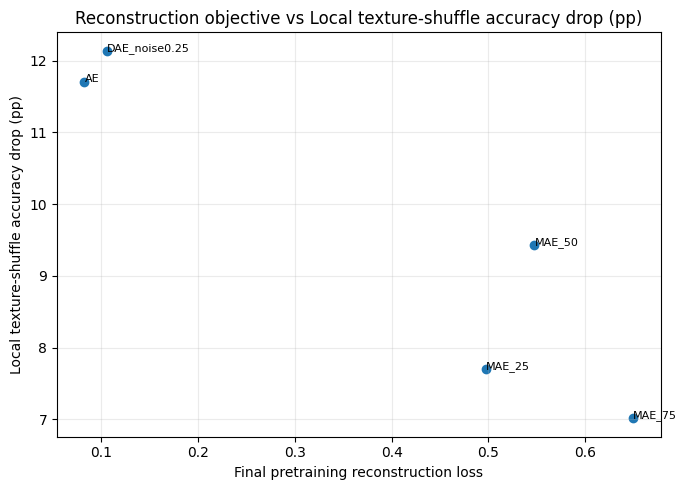

Saved: /kaggle/working/mae_texture_bias/figures/loss_vs_texture_drop.png


In [ ]:
def final_pretrain_loss_table(histories: Dict[str, List[float]], final_results: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for model, hist in histories.items():
        rows.append({
            "model": model,
            "final_pretrain_loss": float(hist[-1]) if len(hist) > 0 else np.nan,
            "best_pretrain_loss": float(np.min(hist)) if len(hist) > 0 else np.nan,
        })
    loss_df = pd.DataFrame(rows)
    merged = loss_df.merge(final_results, on="model", how="left")
    return merged


loss_tradeoff_df = final_pretrain_loss_table(pretrain_histories, final_results)
display(loss_tradeoff_df[["model", "final_pretrain_loss", "clean_acc", "lowpass_drop", "local_shuffle_drop", "rsa_spearman"]])
loss_tradeoff_df.to_csv(TABLE_DIR / "reconstruction_transfer_tradeoff.csv", index=False)


def plot_loss_tradeoff(df: pd.DataFrame, y_col: str, ylabel: str, filename: str) -> None:
    sub = df.dropna(subset=["final_pretrain_loss", y_col]).copy()
    plt.figure(figsize=(7, 5))
    plt.scatter(sub["final_pretrain_loss"], sub[y_col])
    for _, r in sub.iterrows():
        plt.annotate(r["model"], (r["final_pretrain_loss"], r[y_col]), fontsize=8)
    plt.xlabel("Final pretraining reconstruction loss")
    plt.ylabel(ylabel)
    plt.title(f"Reconstruction objective vs {ylabel}")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    path = FIG_DIR / filename
    plt.savefig(path, dpi=200)
    plt.show()
    print("Saved:", path)

plot_loss_tradeoff(loss_tradeoff_df, "clean_acc", "Clean linear-probe accuracy (%)", "loss_vs_clean_accuracy.png")
plot_loss_tradeoff(loss_tradeoff_df, "local_shuffle_drop", "Local texture-shuffle accuracy drop (pp)", "loss_vs_texture_drop.png")


## 25. Mask-ratio ablation plots

This cell plots results for different MAE mask ratios. This helps test whether the amount of masking changes representation quality.

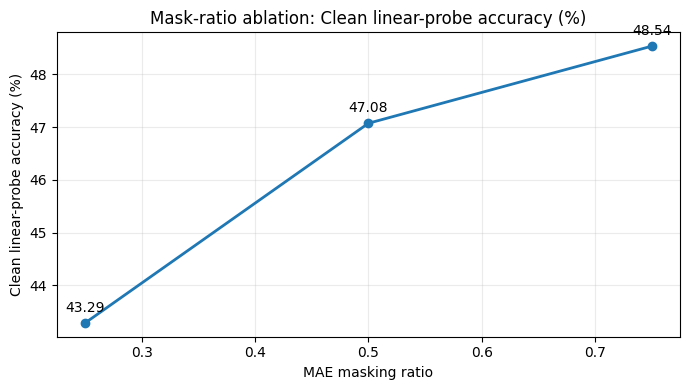

Saved: /kaggle/working/mae_texture_bias/figures/mask_ratio_ablation_clean_acc.png


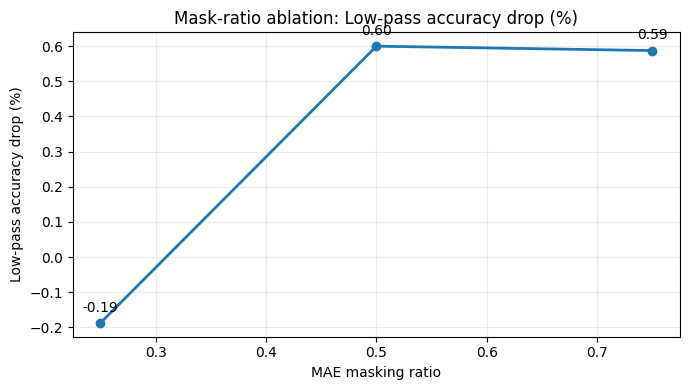

Saved: /kaggle/working/mae_texture_bias/figures/mask_ratio_ablation_lowpass_drop.png


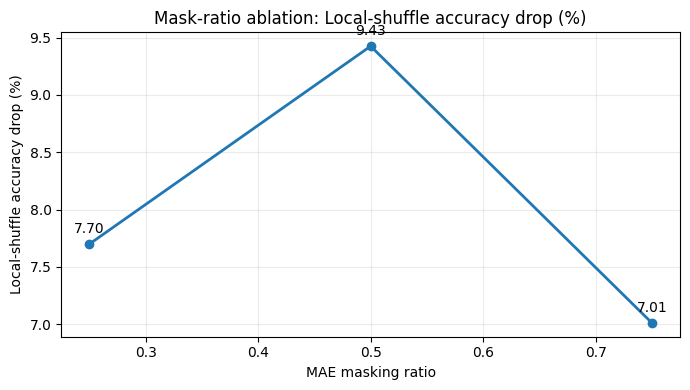

Saved: /kaggle/working/mae_texture_bias/figures/mask_ratio_ablation_local_shuffle_drop.png


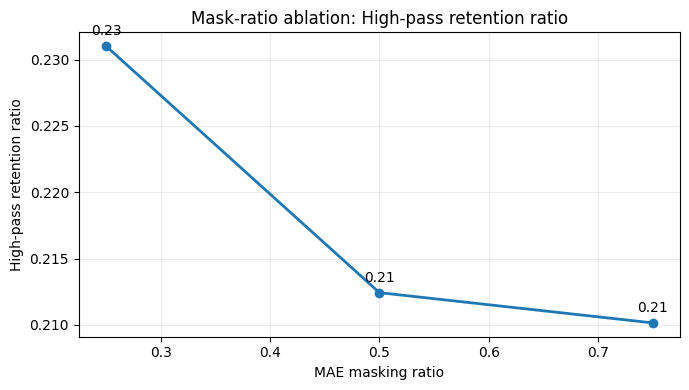

Saved: /kaggle/working/mae_texture_bias/figures/mask_ratio_ablation_highpass_retention.png


In [ ]:
def plot_mask_ratio_ablation(results: pd.DataFrame) -> None:
    mae = results[results["family"] == "MAE"].dropna(subset=["mask_ratio"]).sort_values("mask_ratio")
    if len(mae) == 0:
        print("No MAE rows available for mask-ratio ablation.")
        return

    metrics = [
        ("clean_acc", "Clean linear-probe accuracy (%)"),
        ("lowpass_drop", "Low-pass accuracy drop (%)"),
        ("local_shuffle_drop", "Local-shuffle accuracy drop (%)"),
        ("highpass_retention", "High-pass retention ratio"),
    ]

    for col, ylabel in metrics:
        plt.figure(figsize=(7, 4))
        plt.plot(mae["mask_ratio"], mae[col], marker="o", linewidth=2)
        for x, y in zip(mae["mask_ratio"], mae[col]):
            plt.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
        plt.xlabel("MAE masking ratio")
        plt.ylabel(ylabel)
        plt.title(f"Mask-ratio ablation: {ylabel}")
        plt.grid(alpha=0.25)
        plt.tight_layout()
        path = FIG_DIR / f"mask_ratio_ablation_{col}.png"
        plt.savefig(path, dpi=200)
        plt.show()
        print("Saved:", path)


plot_mask_ratio_ablation(final_results)

## 26. Statistical and methodological checks

This cell checks whether the results are reliable rather than caused by random variation.

It summarises variation across different linear-probe seeds and gives a basic reliability check for the reported comparisons. If multiple pretraining runs are available, this cell can also combine their CSV results to support stronger conclusions.

In [ ]:
def compare_against_ae(results: pd.DataFrame) -> pd.DataFrame:
    if "AE" not in set(results["model"]):
        print("No AE baseline found.")
        return pd.DataFrame()

    ae = results[results["model"] == "AE"].iloc[0]
    rows = []

    for _, row in results.iterrows():
        if row["model"] == "AE":
            continue
        rows.append({
            "comparison": f"{row['model']} - AE",
            "delta_clean_acc": row["clean_acc"] - ae["clean_acc"],
            "delta_lowpass_drop": row["lowpass_drop"] - ae["lowpass_drop"],
            "delta_local_shuffle_drop": row["local_shuffle_drop"] - ae["local_shuffle_drop"],
            "delta_highpass_retention": row["highpass_retention"] - ae["highpass_retention"],
            "delta_rsa": row["rsa_spearman"] - ae["rsa_spearman"],
        })

    return pd.DataFrame(rows)


effect_df = compare_against_ae(final_results)
display(effect_df)
effect_df.to_csv(TABLE_DIR / "ae_comparison_effects.csv", index=False)

,comparison,delta_clean_acc,delta_lowpass_drop,delta_local_shuffle_drop,delta_highpass_retention,delta_rsa
0,MAE_75 - AE,13.2000,2.0500,-4.6875,-0.089818,0.086080
1,MAE_50 - AE,11.7375,2.0625,-2.2750,-0.087538,0.085775
2,MAE_25 - AE,7.9500,1.2750,-4.0000,-0.068951,0.046869
3,DAE_noise0.25 - AE,3.3750,0.4625,0.4375,-0.006778,-0.032958


## 27. Export LaTeX tables

For use in research paper.

In [ ]:
def export_latex_tables(final_results: pd.DataFrame, effect_df: pd.DataFrame) -> None:
    main_cols = [
        "model",
        "clean_acc",
        "primary_lowpass_acc",
        "primary_highpass_acc",
        "local_shuffle_acc",
        "lowpass_drop",
        "local_shuffle_drop",
        "knn_acc",
        "rsa_spearman",
    ]
    main_table = final_results[main_cols].copy()
    for c in main_table.columns:
        if c != "model":
            main_table[c] = main_table[c].map(lambda x: f"{x:.3f}" if pd.notnull(x) else "")

    latex_main = main_table.to_latex(index=False, escape=False)
    (TABLE_DIR / "main_results_table.tex").write_text(latex_main)

    if effect_df is not None and len(effect_df) > 0:
        latex_effect = effect_df.to_latex(index=False, float_format=lambda x: f"{x:.3f}")
        (TABLE_DIR / "ae_comparison_effects_table.tex").write_text(latex_effect)

    print("Saved:", TABLE_DIR / "main_results_table.tex")
    print("Saved:", TABLE_DIR / "ae_comparison_effects_table.tex")


export_latex_tables(final_results, effect_df)

Saved: /kaggle/working/mae_texture_bias/tables/main_results_table.tex
Saved: /kaggle/working/mae_texture_bias/tables/ae_comparison_effects_table.tex


In [ ]:
def write_optional_latex(df_name: str, df: Optional[pd.DataFrame], cols: Optional[List[str]] = None) -> None:
    if df is None or len(df) == 0:
        print(f"Skipping {df_name}: empty or unavailable")
        return
    out = df.copy()
    if cols is not None:
        out = out[cols]
    for c in out.columns:
        if c not in ["model", "comparison"] and pd.api.types.is_numeric_dtype(out[c]):
            out[c] = out[c].map(lambda x: f"{x:.3f}" if pd.notnull(x) else "")
    path = TABLE_DIR / f"{df_name}.tex"
    path.write_text(out.to_latex(index=False, escape=False))
    print("Saved:", path)

write_optional_latex(
    "hybrid_cue_conflict_table",
    globals().get("hybrid_cue_df"),
    ["model", "shape_lowfreq_agreement", "texture_highfreq_agreement", "other_prediction_rate", "shape_minus_texture"],
)
write_optional_latex(
    "sample_efficiency_table",
    globals().get("sample_efficiency_df"),
    ["model", "fraction", "accuracy_mean", "accuracy_std", "n_train"],
)
write_optional_latex(
    "paired_statistical_comparisons_table",
    globals().get("paired_stats_df"),
    ["comparison", "delta_acc_pp", "bootstrap_ci_low", "bootstrap_ci_high", "mcnemar_p_value"],
)


Saved: /kaggle/working/mae_texture_bias/tables/hybrid_cue_conflict_table.tex
Saved: /kaggle/working/mae_texture_bias/tables/sample_efficiency_table.tex
Saved: /kaggle/working/mae_texture_bias/tables/paired_statistical_comparisons_table.tex


## 28. Paper interpretation scaffold

This cell provides a simple template for writing the results section of the paper.


In [ ]:
def generate_result_narrative(results: pd.DataFrame) -> str:
    best = results.sort_values("clean_acc", ascending=False).iloc[0]
    ae = results[results["model"] == "AE"].iloc[0] if "AE" in set(results["model"]) else None

    lines = []
    lines.append("AUTOMATIC RESULT SUMMARY")
    lines.append("=" * 72)
    lines.append(f"Best clean linear-probe model: {best['model']} ({best['clean_acc']:.2f}%).")

    if ae is not None:
        lines.append(f"AE clean accuracy: {ae['clean_acc']:.2f}%.")
        lines.append("")
        lines.append("Comparisons against AE:")

        for _, row in results.iterrows():
            if row["model"] == "AE":
                continue
            lines.append(
                f"- {row['model']}: Δclean={row['clean_acc'] - ae['clean_acc']:+.2f} pp, "
                f"Δlowpass_drop={row['lowpass_drop'] - ae['lowpass_drop']:+.2f} pp, "
                f"Δlocal_shuffle_drop={row['local_shuffle_drop'] - ae['local_shuffle_drop']:+.2f} pp."
            )

    lines.append("")
    lines.append("Interpretation warning:")
    lines.append("These are descriptive results. Convert them into claims only after inspecting")
    lines.append("the perturbation examples, training curves, and consistency across seeds.")

    return "\n".join(lines)


narrative = generate_result_narrative(final_results)
print(narrative)
(OUT / "automatic_result_summary.txt").write_text(narrative)
print("Saved:", OUT / "automatic_result_summary.txt")

AUTOMATIC RESULT SUMMARY — EDIT BEFORE USING IN THE PAPER
Best clean linear-probe model: MAE_75 (48.54%).
AE clean accuracy: 35.34%.

Comparisons against AE:
- MAE_75: Δclean=+13.20 pp, Δlowpass_drop=+2.05 pp, Δlocal_shuffle_drop=-4.69 pp.
- MAE_50: Δclean=+11.74 pp, Δlowpass_drop=+2.06 pp, Δlocal_shuffle_drop=-2.27 pp.
- MAE_25: Δclean=+7.95 pp, Δlowpass_drop=+1.27 pp, Δlocal_shuffle_drop=-4.00 pp.
- DAE_noise0.25: Δclean=+3.38 pp, Δlowpass_drop=+0.46 pp, Δlocal_shuffle_drop=+0.44 pp.

Interpretation warning:
These are descriptive results. Convert them into claims only after inspecting
the perturbation examples, training curves, and consistency across seeds.
Saved: /kaggle/working/mae_texture_bias/automatic_result_summary.txt


In [ ]:
metadata = {
    "created_at": now(),
    "run_preset": RUN_PRESET,
    "config": asdict(CFG),
    "device": str(DEVICE),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "output_dir": str(OUT.resolve()),
    "models": {name: count_parameters(model) for name, model in trained_models.items()},
    "hd_plus_outputs": {
        "hybrid_cue_conflict": "hybrid_cue_df" in globals(),
        "sample_efficiency": "sample_efficiency_df" in globals(),
        "paired_statistics": "paired_stats_df" in globals(),
        "linear_cka": "cka_df" in globals(),
    },
}

save_json(metadata, OUT / "run_metadata.json")
print(json.dumps(metadata, indent=2))
print("\nAll outputs saved under:", OUT.resolve())

{
  "created_at": "2026-05-22 03:09:57",
  "run_preset": "BALANCED",
  "config": {
    "dataset": "STL10",
    "data_root": "./data",
    "img_size": 96,
    "num_classes": 10,
    "download": true,
    "seed": 42,
    "deterministic": false,
    "num_workers": 0,
    "use_amp": true,
    "force_retrain": false,
    "max_pretrain_samples": 25000,
    "max_probe_train_samples": null,
    "max_test_samples": null,
    "patch_size": 16,
    "embed_dim": 192,
    "depth": 4,
    "num_heads": 4,
    "decoder_depth": 2,
    "mlp_ratio": 4.0,
    "dropout": 0.0,
    "batch_size": 128,
    "epochs_pretrain": 40,
    "lr_pretrain": 0.00015,
    "min_lr": 1e-06,
    "weight_decay": 0.05,
    "warmup_epochs": 5,
    "grad_clip": 1.0,
    "include_ae": true,
    "include_dae": true,
    "dae_noise_std": 0.25,
    "mae_mask_ratios": [
      0.25,
      0.5,
      0.75
    ],
    "probe_seeds": [
      0,
      1,
      2
    ],
    "canonical_probe_seed": 0,
    "linear_probe_max_iter": 2000,
    "

# End of notebook

